# Task 3 – CIGRE-Mittelspannungsnetz

**Ziel:** Das Mittelspannungs-Testnetz CIGRE-MV wird in pandapower aufgebaut, mit einem Lastfluss berechnet und ausgewertet (Busspannungen, Leitungsauslastungen). Anschließend wird es um das Ortsnetz aus Task 2 mit saisonaler Einspeisung erweitert.

**Aufbau des Notebooks:**

1. Daten laden: Lastprofil der Haushalte, Windenergieanlage, PV-Anlage, Wetterdaten
2. Netzaufbau CIGRE-MV: Netzplan und Komponenten
3. Lastfluss, Ergebnisse und Auswertung (statisch und saisonal über 12 typische Wochen)
4. Erweiterung um das Ortsnetz aus Task 2 *(folgt)*

## Importe

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pandapower as pp
import pandapower.networks as pn

# Alle Module liegen im Ordner dieses Notebooks (task3)
TASK3 = Path(".")
import profiles as pr
import weather as wt
from profiles import Lastprofil, Month, DayType, Season

import plots

import warnings
warnings.simplefilter(action="ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

# 20 unterscheidbare Farben, damit alle 15 Busse in einem Diagramm unterscheidbar bleiben
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=plt.cm.tab20.colors)

Module im Ordner `task3` (Beschreibung siehe `README.md`):

- `profiles.py`: Einlesen und Aufbereiten der BDEW-Standardlastprofile 2025 (Wochen bilden, Dynamisierung, Skalierung), übernommen aus Task 2 und erweitert
- `weather.py`: Wetterdaten (Open-Meteo) und Umrechnung in PV- und Windleistung über die Kennlinien, übernommen aus Task 2
- `plots.py`: Diagramme mit einheitlicher Zeitachse (Uhrzeit im 6-Stunden-Takt, Tageswechsel als senkrechte Linie, Datum über jedem Tag) Komponentenübersicht des Netzes und `table()` für formatierte Tabellen (farbig, wenn `jinja2` installiert ist)
- `simulation.py`, `elements.py`, `timeseries.py`, `diagrams.py`: Simulationssoftware für die saisonale Lastflussrechnung (Abschnitt 3.2)

In [2]:
def monatstabelle(s, groesse, stat="max", elemente=None):
    """Monatstabelle (Elemente × Monate) einer Simulation, farbig hinterlegt.
    groesse: "Spannung", "Winkel", "Leitung" oder "Trafo"; stat: "max", "min" oder "mean"."""
    art = {  # Ergebnistabelle, Titel, Zahlenformat, Farbskala, Bereich der Farbskala
        "Spannung": ("vm_pu", "U {} [pu]", "{:.3f}",
                     "RdYlGn_r" if stat == "max" else "RdYlGn", (1.0, 1.08) if stat == "max" else (0.92, 1.03)),
        "Winkel":   ("va_degree", "Winkel {} [°]", "{:.2f}", "coolwarm", (None, None)),
        "Leitung":  ("line_loading", "Leitung {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
        "Trafo":    ("trafo_loading", "Trafo {} [%]", "{:.1f}", "YlOrRd", (0, 100)),
    }
    attr, titel, fmt, cmap, (vmin, vmax) = art[groesse]
    df = getattr(s.results, attr)
    if elemente is not None:
        df = df[elemente]
    monat = s.results.info["month"].map(lambda m: Month[m].label)
    t = df.groupby(monat).agg(stat).T[[m.label for m in Month]]
    t.index.name = titel.format(stat)
    return t.style.format(fmt, na_rep="–").background_gradient(cmap=cmap, vmin=vmin, vmax=vmax, axis=None)

## 1 Daten laden

Alle Eingangsdaten werden einmal zu Beginn geladen und stehen danach in Variablen zur Verfügung:

| Variable | Datei | Inhalt |
|---|---|---|
| `PROFILES` | `data/BDEW_H25_Haushalte.csv`, `data/BDEW_G25_Gewerbe.csv` | BDEW-Standardlastprofile H25 (Haushalt) und G25 (Gewerbe), je 12 Monate × 3 Tagtypen × 96 Viertelstunden |
| `WEATHER` | `data/weather_weeks_2025.csv` | je Monat eine typische Woche (stündlich) mit Wetter und berechneter PV- und Windleistung |

Die Wetterdaten wurden in Task 2 einmalig über die Open-Meteo-API abgerufen und als CSV gespeichert; das Notebook benötigt deshalb keinen Internetzugang.

In [3]:
DATA = TASK3 / "data"
WEATHER_FILE = DATA / "weather_weeks_2025.csv"

PROFILES = pr.load_profiles(DATA)
WEATHER = wt.load_weather_weeks(WEATHER_FILE)                  # {Month: DataFrame mit 168 Stunden}
WEEK_STARTS = {m: df.index[0] for m, df in WEATHER.items()}     # Montag jeder Wetterwoche

ANNUAL_KWH = 3500                                               # Jahresverbrauch eines Haushalts [kWh/a]

for profil, df in PROFILES.items():
    print(f"{profil.label}: {df.shape[0]} Viertelstunden × {df.shape[1]} Spalten (Monat, Tagtyp)")
print(f"Wetter:     {len(WEATHER)} Wochen × {len(next(iter(WEATHER.values())))} Stunden")

H25 – Haushalt: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
G25 – Gewerbe allgemein: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
L25 – Landwirtschaft: 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
P25 – Haushalt mit PV (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
S25 – Haushalt mit PV und Speicher (Netzbezug): 96 Viertelstunden × 36 Spalten (Monat, Tagtyp)
Wetter:     12 Wochen × 168 Stunden


## 3 Lastfluss und Auswertung

Die Auswertung erfolgt in zwei Stufen:

1. **Statischer Lastfluss (Punkte 2 bis 4 des Arbeitsauftrags):** Das CIGRE-Netz wird mit den in [13] angegebenen Leistungen berechnet. Alle Lasten und Erzeuger arbeiten dabei gleichzeitig mit ihrer Bemessungsleistung. Das ist ein einzelner, sehr ungünstiger Betriebspunkt.
2. **Saisonale Simulation:** Lasten und Erzeuger folgen den BDEW-Lastprofilen und den Wetterdaten. Für jeden Monat wird eine typische Woche stündlich berechnet (12 × 168 = 2016 Lastflüsse).

### 3.1 Statischer Lastfluss

Der Lastfluss wird mit dem Standardverfahren von pandapower gelöst (Newton-Raphson, `pp.runpp`). Konvergiert die Berechnung nicht, löst pandapower `LoadflowNotConverged` aus; zusätzlich wird `net.converged` geprüft.

In [4]:
net = pn.create_cigre_network_mv(with_der="pv_wind")

try:
    pp.runpp(net, algorithm="nr")
except pp.LoadflowNotConverged:
    raise RuntimeError("Der Lastfluss ist nicht konvergiert.")

assert net.converged, "Der Lastfluss ist nicht konvergiert."
print(f"Lastfluss konvergiert: {net.converged}")
print(f"Iterationen (Newton-Raphson): {net._ppc['iterations']}")
print(f"Last gesamt:      {net.load.p_mw.sum():6.2f} MW")
print(f"Erzeugung gesamt: {net.sgen.p_mw.sum():6.2f} MW")
print(f"Bezug aus 110 kV: {net.res_ext_grid.p_mw.sum():6.2f} MW")
print(f"Trafoauslastung:  " + ", ".join(f"{n} {v:.1f} %" for n, v in zip(net.trafo.name, net.res_trafo.loading_percent)))
print(f"Netzverluste:     {net.res_line.pl_mw.sum() + net.res_trafo.pl_mw.sum():6.3f} MW")

Lastfluss konvergiert: True
Iterationen (Newton-Raphson): 4
Last gesamt:       44.74 MW
Erzeugung gesamt:   1.71 MW
Bezug aus 110 kV:  43.20 MW
Trafoauslastung:  Trafo 0-1 93.8 %, Trafo 0-12 84.7 %
Netzverluste:      0.164 MW


**Busspannungen.** Die Ergebnistabelle `net.res_bus` enthält die Spannung in pu. Zusätzlich sind die Spannung in kV und die Abweichung von der Nennspannung angegeben. Grenzen nach DIN EN 50160: 0,90 bis 1,10 pu.

In [5]:
V_MIN, V_MAX = 0.90, 1.10

bus_static = pd.DataFrame({
    "Bus": net.bus.name,
    "U_n [kV]": net.bus.vn_kv,
    "U [pu]": net.res_bus.vm_pu.round(4),
    "U [kV]": (net.res_bus.vm_pu * net.bus.vn_kv).round(3),
    "Abweichung [%]": ((net.res_bus.vm_pu - 1) * 100).round(2),
    "Winkel [°]": net.res_bus.va_degree.round(2),
})
bus_static["im Band 0,9–1,1"] = bus_static["U [pu]"].between(V_MIN, V_MAX).map({True: "ja", False: "nein"})
bus_static.set_index("Bus")

,U_n [kV],U [pu],U [kV],Abweichung [%],Winkel [°],"im Band 0,9–1,1"
Bus,,,,,,
Bus 0,110.0,1.0300,113.300,3.00,0.00,ja
Bus 1,20.0,0.9941,19.883,-0.59,-36.05,ja
Bus 2,20.0,0.9778,19.556,-2.22,-36.57,ja
Bus 3,20.0,0.9518,19.037,-4.82,-37.41,ja
Bus 4,20.0,0.9501,19.002,-4.99,-37.51,ja
Bus 5,20.0,0.9489,18.978,-5.11,-37.57,ja
Bus 6,20.0,0.9475,18.950,-5.25,-37.65,ja
Bus 7,20.0,0.9522,19.044,-4.78,-37.14,ja
Bus 8,20.0,0.9492,18.984,-5.08,-37.41,ja


**Leitungsauslastung.** `net.res_line.loading_percent` gibt den Strom bezogen auf den thermisch zulässigen Strom `max_i_ka` an. Die Leitungen 6-7, 11-4 und 14-8 sind über die offenen Trennschalter S2, S3 und S1 an einem Ende aufgetrennt. Durch sie fließt nur der kapazitive Ladestrom.

In [6]:
open_lines = set(net.switch.query("et == 'l' and not closed").element)

line_static = pd.DataFrame({
    "Leitung": net.line.name,
    "von": net.bus.name.loc[net.line.from_bus].values,
    "nach": net.bus.name.loc[net.line.to_bus].values,
    "Art": net.line.type.map({"cs": "Kabel", "ol": "Freileitung"}),
    "Länge [km]": net.line.length_km,
    "I_max [A]": (net.line.max_i_ka * 1000).round(0),
    "I [A]": (net.res_line.i_ka * 1000).round(1),
    "Auslastung [%]": net.res_line.loading_percent.round(1),
    "Verluste [kW]": (net.res_line.pl_mw * 1000).round(1),
})
line_static["Schalter"] = ["offen" if i in open_lines else "geschlossen" for i in net.line.index]
line_static.set_index("Leitung")

,von,nach,Art,Länge [km],I_max [A],I [A],Auslastung [%],Verluste [kW],Schalter
Leitung,,,,,,,,,
Line 1-2,Bus 1,Bus 2,Kabel,2.82,145.0,87.9,60.6,32.5,geschlossen
Line 2-3,Bus 2,Bus 3,Kabel,4.42,145.0,88.9,61.3,51.9,geschlossen
Line 3-4,Bus 3,Bus 4,Kabel,0.61,145.0,50.9,35.1,2.4,geschlossen
Line 4-5,Bus 4,Bus 5,Kabel,0.56,145.0,38.0,26.2,1.2,geschlossen
Line 5-6,Bus 5,Bus 6,Kabel,1.54,145.0,16.3,11.2,0.6,geschlossen
Line 7-8,Bus 7,Bus 8,Kabel,1.67,145.0,43.2,29.8,4.7,geschlossen
Line 8-9,Bus 8,Bus 9,Kabel,0.32,145.0,45.1,31.1,1.0,geschlossen
Line 9-10,Bus 9,Bus 10,Kabel,0.77,145.0,26.1,18.0,0.8,geschlossen
Line 10-11,Bus 10,Bus 11,Kabel,0.33,145.0,10.0,6.9,0.0,geschlossen


**Diagramme.** Spannungen aller Busse mit dem Spannungsband nach DIN EN 50160 und Auslastung aller Leitungen mit Markierung bei 100 %. Leitungen mit offenem Trennschalter sind grau dargestellt.

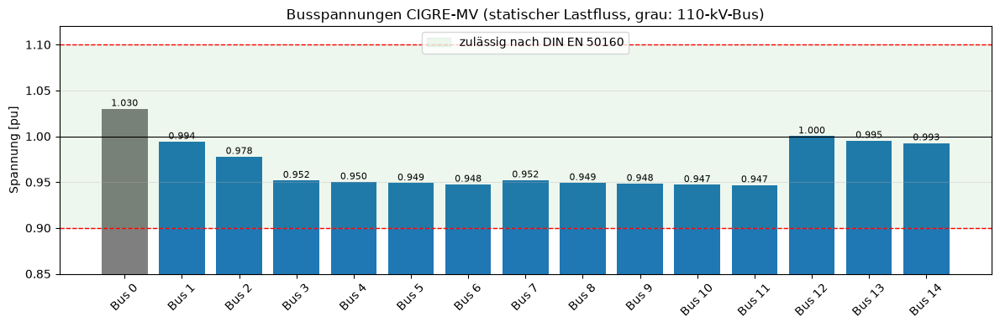

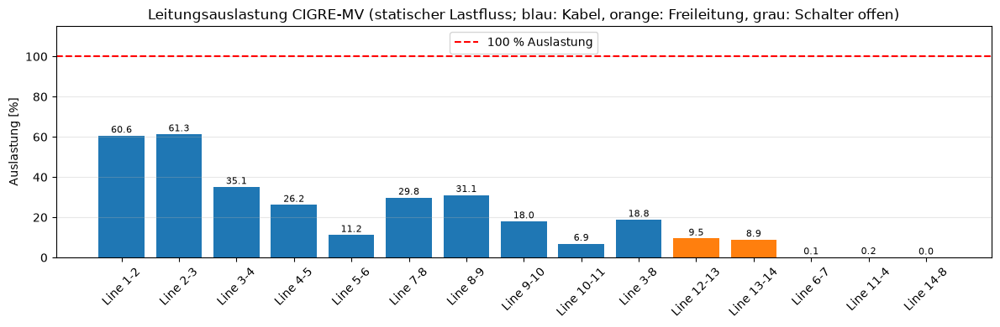

In [7]:
fig, ax = plt.subplots(figsize=(12, 4))
colors = ["tab:gray" if v == 110 else "tab:blue" for v in net.bus.vn_kv]
ax.bar(bus_static["Bus"], bus_static["U [pu]"], color=colors)
ax.axhspan(V_MIN, V_MAX, color="tab:green", alpha=0.08, label="zulässig nach DIN EN 50160")
ax.axhline(V_MIN, color="red", ls="--", lw=1)
ax.axhline(V_MAX, color="red", ls="--", lw=1)
ax.axhline(1.0, color="black", lw=0.8)
for x, v in enumerate(bus_static["U [pu]"]):
    ax.text(x, v + 0.003, f"{v:.3f}", ha="center", fontsize=8)
ax.set_ylim(0.85, 1.12)
ax.set_ylabel("Spannung [pu]")
ax.set_title("Busspannungen CIGRE-MV (statischer Lastfluss, grau: 110-kV-Bus)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
colors = ["lightgray" if s == "offen" else ("tab:orange" if a == "Freileitung" else "tab:blue")
          for s, a in zip(line_static["Schalter"], line_static["Art"])]
ax.bar(line_static["Leitung"], line_static["Auslastung [%]"], color=colors)
ax.axhline(100, color="red", ls="--", lw=1.5, label="100 % Auslastung")
for x, v in enumerate(line_static["Auslastung [%]"]):
    ax.text(x, v + 1.5, f"{v:.1f}", ha="center", fontsize=8)
ax.set_ylim(0, 115)
ax.set_ylabel("Auslastung [%]")
ax.set_title("Leitungsauslastung CIGRE-MV (statischer Lastfluss; blau: Kabel, orange: Freileitung, grau: Schalter offen)")
ax.tick_params(axis="x", rotation=45)
ax.legend(loc="upper center")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Netzplan mit den Ergebnissen des statischen Lastflusses.** Die Busse sind nach ihrer Spannung eingefärbt (0,8 bis 1,2 pu: lila – blau – grün bei 1,0 pu – gelb – rot). Leitungen und Transformatoren sind nach ihrer Auslastung eingefärbt (grün – gelb – rot, schwarz über 100 %). Schalter sind Quadrate: schwarz = geschlossen, weiß = offen. Lasten sind Pfeile, Erzeuger Kreise mit G. Daneben stehen Name, Profil und Leistung.

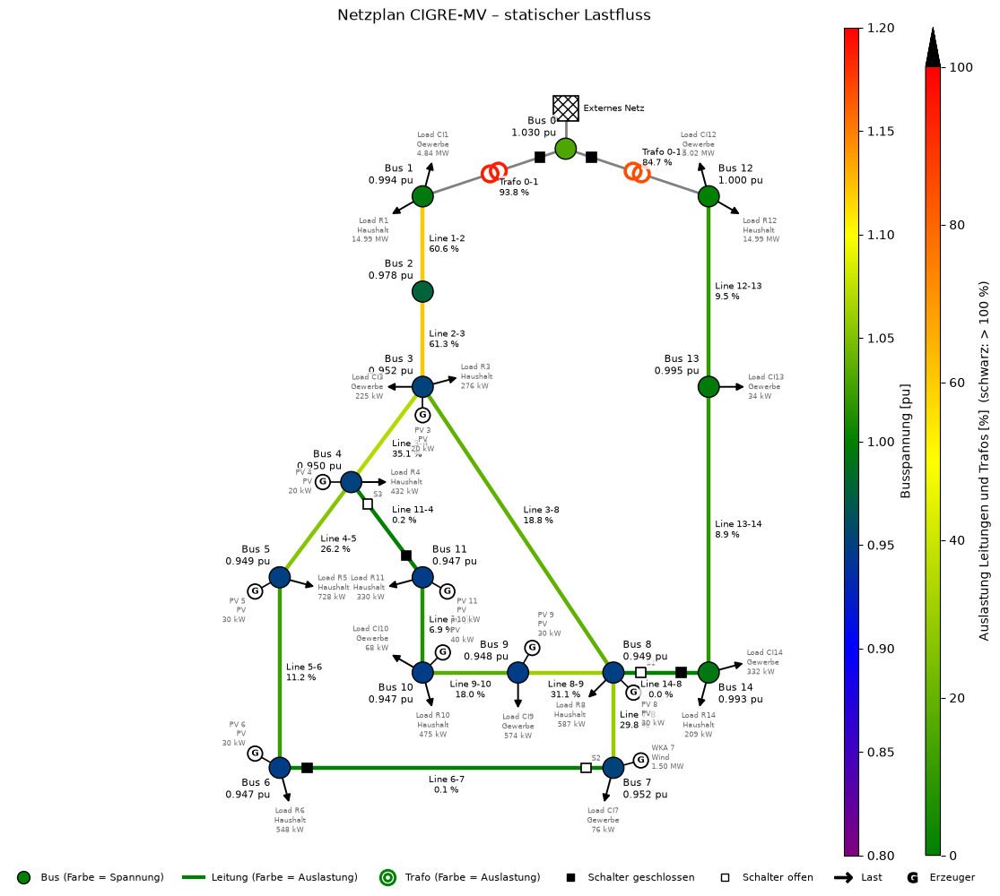

In [8]:
import netplan

netplan.plot_static(net, title="Netzplan CIGRE-MV – statischer Lastfluss");

**Kennzahlen statischer Lastfluss**

| Größe | Wert | Ort |
|---|---|---|
| Konvergenz | ja, 4 Newton-Raphson-Iterationen | – |
| niedrigste Spannung (20 kV) | 0,947 pu (−5,3 %) | Bus 11 |
| höchste Spannung (20 kV) | 1,000 pu | Bus 12 |
| höchste Leitungsauslastung | 61,3 % | Line 2-3 (Line 1-2: 60,6 %) |
| Trafoauslastung | 93,8 % bzw. 84,7 % | Trafo 0-1 bzw. Trafo 0-12 |
| Bezug aus dem 110-kV-Netz | 43,2 MW bei 44,7 MW Last und 1,7 MW Erzeugung | – |
| Netzverluste | 0,16 MW (0,4 % der Last) | – |

**Interpretation.** Alle Busspannungen liegen im Band 0,9 bis 1,1 pu nach DIN EN 50160. Keine Leitung ist überlastet. Den größten Spannungsfall gibt es in Abgang 1. Über die Kabel Line 1-2 und Line 2-3 (zusammen 7,2 km) fließt die gesamte Last hinter Bus 2, die Spannung fällt dort von 0,994 auf 0,952 pu. Dahinter sind die Kabel kurz und schwächer belastet, die Spannung sinkt nur noch bis 0,947 pu. Abgang 2 (Freileitungen) versorgt außer der großen Last an Bus 12 nur kleine Lasten. Die Spannung bleibt dort nahe 1,0 pu.

Am stärksten belastet sind die Transformatoren (bis 94 %). Sie tragen die großen Ersatzlasten an Bus 1 und Bus 12. Weil die Transformatoren keinen Stufensteller haben, fällt die Spannung bereits zwischen dem 110-kV-Netz (1,03 pu) und Bus 1 auf 0,994 pu.

Der statische Fall ist ein Grenzfall: Alle Lasten und alle Erzeuger arbeiten gleichzeitig mit ihrer Bemessungsleistung. Die Windenergieanlage (1,5 MW an Bus 7) entlastet dabei die Leitungen 1-2 und 2-3. Ohne die dezentralen Erzeuger (`with_der=False`) sinkt die Spannung auf 0,923 pu und Line 2-3 ist zu 97 % ausgelastet. Wie aussagekräftig der statische Fall ist, hängt also stark davon ab, ob Wind und PV zum Zeitpunkt der Höchstlast tatsächlich einspeisen. Das untersucht die saisonale Simulation.

**Literaturabgleich.** DIN EN 50160 fordert in Mittelspannungsnetzen, dass 99 % der 10-Minuten-Mittelwerte einer Woche innerhalb von ±10 % der vereinbarten Versorgungsspannung liegen. Diese Bedingung ist erfüllt. In der Netzplanung steht der Mittelspannung allerdings nur ein Teil dieses Bandes zur Verfügung, weil auch im Ortsnetztransformator und im Niederspannungsnetz Spannung abfällt. Ein Spannungsfall von gut 5 % im Mittelspannungsnetz ist deshalb zulässig, verbraucht aber einen merklichen Teil der Reserve. Die Kabelabgänge des CIGRE-Netzes sind als offene Ringe aufgebaut (S2, S3). Fällt ein Abschnitt aus, wird der Ring über den Trennschalter geschlossen und eine Seite übernimmt zusätzliche Last. Die Reserve von knapp 40 % auf Line 1-2 und Line 2-3 ist deshalb für die Wiederversorgung wichtig [13]. Die Netzparameter entsprechen [13] in der Umsetzung von pandapower [14].

### 3.2 Saisonale Simulation

Für die saisonale Simulation wird die Simulationssoftware aus `simulation.py` verwendet (Beschreibung siehe `README.md`). Die Profile werden über die Elementnamen zugeordnet:

| Element | Profil | Skalierung |
|---|---|---|
| `Load R…` (Wohngebiete) | BDEW H25 mit Dynamisierung | `p_mw` aus [13] = höchste Stundenleistung im Jahr |
| `Load CI…` (Gewerbe/Industrie) | BDEW G25 | `p_mw` aus [13] = höchste Stundenleistung im Jahr |
| `PV …` | Wetter (Einstrahlung, Temperatur), Modul Trina Vertex S+ | `p_mw` aus [13] = installierte Leistung aller PV-Anlagen am Bus |
| `WKA 7` | Wetter (Wind auf Nabenhöhe), Kennlinie Vestas V90-2.0 MW | `p_mw` aus [13] = Nennleistung |

Der Jahresverbrauch jeder Last wird so gewählt, dass die höchste Stundenleistung des Profils im Jahr 2025 genau dem Wert `p_mw` aus dem CIGRE-Netz entspricht. Der Leistungsfaktor der Lasten bleibt wie in [13]. Simuliert wird je Monat eine typische Woche (Montag bis Sonntag, stündlich).

**Zur PV-Skalierung:** Ein `sgen` steht nicht für ein einzelnes Modul, sondern für die gesamte PV-Leistung am Bus. Das Modul Trina Vertex S+ liefert nur den zeitlichen Verlauf je kWp (Einstrahlung, Temperatur, Wirkungsgrad). Dieser Verlauf wird mit der installierten Leistung multipliziert. `PV 3` mit 0,02 MW entspricht also 20 kWp, das sind rund 43 Module mit 460 W. Zusammen sind im CIGRE-Netz 0,21 MWp PV installiert, das entspricht etwa 460 Modulen bzw. 20 bis 40 Dachanlagen. Gemessen an der Last von 44,7 MW ist das sehr wenig. Mehr PV lässt sich mit `changeParameter("PV 3", "kwp", …)` oder zusätzlichen Erzeugern (`createElement(Generator(…))`) untersuchen.

In [9]:
import simulation as sim
from elements import Diagram, Profile

cigre = sim.init("cigre_mv", pn.create_cigre_network_mv(with_der="pv_wind"), overwrite=True, assignProfiles=True)
cigre

27 Profile zugeordnet: HAUSHALT: 10, GEWERBE: 8, PV: 8, WIND: 1


Simulation 'cigre_mv' (15 bus, 15 line, 2 trafo, 1 ext_grid, 8 switch, 18 load, 9 sgen)
  Herkunft: – | Änderungen: 0 | Ergebnisse: keine | letzter Lauf: –

In [10]:
loads = cigre.elements("load")[["Bus", "Profil", "Skalierung"]]
loads["Höchstleistung [MW]"] = cigre.net.load.set_index("name").loc[loads.index, "p_mw"]
loads

,Bus,Profil,Skalierung,Höchstleistung [MW]
Name,,,,
Load R1,Bus 1,HAUSHALT,66.157.911 kWh/a,14.99400
Load R3,Bus 3,HAUSHALT,1.219.778 kWh/a,0.27645
Load R4,Bus 4,HAUSHALT,1.904.566 kWh/a,0.43165
Load R5,Bus 5,HAUSHALT,3.209.943 kWh/a,0.72750
Load R6,Bus 6,HAUSHALT,2.418.157 kWh/a,0.54805
Load R8,Bus 8,HAUSHALT,2.589.354 kWh/a,0.58685
Load R10,Bus 10,HAUSHALT,2.097.163 kWh/a,0.47530
Load R11,Bus 11,HAUSHALT,1.455.174 kWh/a,0.32980
Load R12,Bus 12,HAUSHALT,66.157.911 kWh/a,14.99400


In [11]:
cigre.runSimulation()

Simulation 'cigre_mv': 2016 Lastflüsse in 103 s, nicht konvergiert: 0


Ergebnisse: 2016 Zeitschritte (2016 konvergiert), Monate: Januar, Februar, März, April, Mai, Juni, Juli, August, September, Oktober, November, Dezember
Tabellen: vm_pu, va_degree, line_loading, line_i_ka, trafo_loading, trafo_p_mw, ext_grid_p_mw, load_p_mw, sgen_p_mw, element_p_mw, info

In [12]:
cigre.summary()

Zeitschritte                                                         2016
konvergiert                                                          2016
U min [pu]                                                          0.951
U max [pu]                                                           1.03
Stunden U < 0.9                                                         0
Stunden U > 1.1                                                         0
Leitung max [%]                                                      75.6
Stunden Leitung > 100 %                                                 0
Trafo max [%]                                                        82.0
Stunden Trafo > 100 %                                                   0
Stunden Rückspeisung ins vorgelagerte Netz                              0
max. Rückspeisung [MW]                                                0.0
Energie Lasten [MWh]                                              43722.0
Energie Erzeuger [MWh]                

In [13]:
cigre.summary(by="month")

,Zeitschritte,konvergiert,U min [pu],U max [pu],Stunden U < 0.9,Stunden U > 1.1,Leitung max [%],Stunden Leitung > 100 %,Trafo max [%],Stunden Trafo > 100 %,Stunden Rückspeisung ins vorgelagerte Netz,max. Rückspeisung [MW],Energie Lasten [MWh],Energie Erzeuger [MWh]
Monat,,,,,,,,,,,,,,
Januar,168,168,0.9523,1.03,0,0,75.1,0,82.0,0,0,0.0,4248.8,117.3
Februar,168,168,0.9510,1.03,0,0,75.6,0,81.4,0,0,0.0,4177.1,78.5
März,168,168,0.9592,1.03,0,0,69.4,0,73.6,0,0,0.0,3881.9,56.0
April,168,168,0.9716,1.03,0,0,57.5,0,65.7,0,0,0.0,3656.1,52.6
Mai,168,168,0.9792,1.03,0,0,49.2,0,55.2,0,0,0.0,3262.5,71.3
Juni,168,168,0.9775,1.03,0,0,52.4,0,57.5,0,0,0.0,3228.4,81.7
Juli,168,168,0.9792,1.03,0,0,50.3,0,56.6,0,0,0.0,3180.9,40.4
August,168,168,0.9804,1.03,0,0,49.3,0,55.4,0,0,0.0,3137.0,51.8
September,168,168,0.9768,1.03,0,0,53.1,0,60.1,0,0,0.0,3225.1,91.9


### 3.3 Spannungen an allen Bussen

Die erste Tabelle fasst die Spannungen jedes Busses über alle 2016 simulierten Stunden zusammen. Die beiden folgenden Tabellen zeigen die niedrigste und die höchste Spannung je Bus und Monat. Alle Stundenwerte stehen zusätzlich in `simulations/cigre_mv/results/vm_pu.csv`.

In [14]:
res = cigre.results
vm = res.vm_pu
fmt_t = lambda s: s.dt.strftime("%a %d.%m. %H:%M")

bus_table = pd.DataFrame({
    "U_n [kV]": cigre.net.bus.set_index("name").loc[vm.columns, "vn_kv"],
    "U min [pu]": vm.min(),
    "Zeitpunkt min": fmt_t(vm.idxmin()),
    "U Mittel [pu]": vm.mean(),
    "U max [pu]": vm.max(),
    "Zeitpunkt max": fmt_t(vm.idxmax()),
    "statisch [pu]": bus_static.set_index("Bus")["U [pu]"],
})
bus_table["Spannweite [%]"] = (bus_table["U max [pu]"] - bus_table["U min [pu]"]) * 100
bus_table.index.name = "Bus"
bus_table.round(4)

,U_n [kV],U min [pu],Zeitpunkt min,U Mittel [pu],U max [pu],Zeitpunkt max,statisch [pu],Spannweite [%]
Bus,,,,,,,,
Bus 0,110.0,1.0300,Mon 06.01. 00:00,1.0300,1.0300,Mon 06.01. 00:00,1.0300,0.0000
Bus 1,20.0,1.0024,Fri 19.12. 17:00,1.0152,1.0246,Mon 08.09. 03:00,0.9941,2.2181
Bus 2,20.0,0.9847,Wed 05.02. 18:00,1.0070,1.0248,Thu 11.09. 03:00,0.9778,4.0046
Bus 3,20.0,0.9567,Wed 05.02. 18:00,0.9937,1.0246,Thu 11.09. 03:00,0.9518,6.7887
Bus 4,20.0,0.9551,Wed 05.02. 18:00,0.9929,1.0242,Thu 11.09. 03:00,0.9501,6.9146
Bus 5,20.0,0.9540,Wed 05.02. 18:00,0.9923,1.0240,Thu 11.09. 03:00,0.9489,7.0010
Bus 6,20.0,0.9527,Wed 05.02. 18:00,0.9917,1.0237,Thu 11.09. 03:00,0.9475,7.1032
Bus 7,20.0,0.9528,Wed 05.02. 18:00,0.9930,1.0278,Sat 14.06. 03:00,0.9522,7.5020
Bus 8,20.0,0.9528,Wed 05.02. 18:00,0.9921,1.0254,Thu 11.09. 03:00,0.9492,7.2612


In [15]:
month_of = res.info["month"].map(lambda m: Month[m].label)
order = [m.label for m in Month]

u_min_month = vm.groupby(month_of).min().T[order]
u_min_month.index.name = "U min [pu]"
plots.table(u_min_month, decimals=3, cmap="RdYlGn", vmin=0.92, vmax=1.03)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U min [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.002,1.003,1.006,1.009,1.012,1.012,1.012,1.013,1.011,1.008,1.004,1.002
Bus 2,0.985,0.985,0.990,0.996,1.001,1.000,1.001,1.002,0.999,0.993,0.986,0.985
Bus 3,0.958,0.957,0.964,0.976,0.983,0.981,0.983,0.984,0.981,0.970,0.959,0.958
Bus 4,0.956,0.955,0.963,0.975,0.982,0.980,0.982,0.983,0.979,0.969,0.958,0.956
Bus 5,0.955,0.954,0.962,0.974,0.982,0.979,0.981,0.982,0.978,0.968,0.957,0.955
Bus 6,0.953,0.953,0.961,0.973,0.981,0.978,0.980,0.981,0.977,0.967,0.955,0.954
Bus 7,0.955,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.955
Bus 8,0.954,0.953,0.961,0.973,0.980,0.979,0.980,0.982,0.978,0.967,0.955,0.954


In [16]:
u_max_month = vm.groupby(month_of).max().T[order]
u_max_month.index.name = "U max [pu]"
plots.table(u_max_month, decimals=3, cmap="RdYlGn_r", vmin=1.0, vmax=1.08)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
U max [pu],,,,,,,,,,,,
Bus 0,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030,1.030
Bus 1,1.022,1.022,1.023,1.023,1.024,1.024,1.024,1.024,1.025,1.024,1.023,1.023
Bus 2,1.022,1.021,1.021,1.022,1.022,1.024,1.022,1.023,1.025,1.023,1.023,1.023
Bus 3,1.021,1.020,1.017,1.019,1.018,1.024,1.019,1.022,1.025,1.021,1.022,1.022
Bus 4,1.021,1.019,1.017,1.019,1.018,1.024,1.018,1.021,1.024,1.021,1.021,1.021
Bus 5,1.020,1.019,1.017,1.019,1.018,1.023,1.018,1.021,1.024,1.021,1.021,1.021
Bus 6,1.020,1.018,1.016,1.018,1.017,1.023,1.018,1.021,1.024,1.020,1.020,1.021
Bus 7,1.025,1.023,1.020,1.022,1.020,1.028,1.020,1.024,1.028,1.024,1.025,1.026
Bus 8,1.022,1.020,1.018,1.020,1.018,1.025,1.019,1.022,1.025,1.022,1.022,1.023


### 3.4 Spannungen Monat für Monat

Je Monat ein Diagramm mit allen Bussen. Rot gestrichelt sind die Grenzen 0,9 und 1,1 pu nach DIN EN 50160 eingezeichnet. Die senkrechte Markierung zeigt den Zeitpunkt der niedrigsten Spannung der Woche.

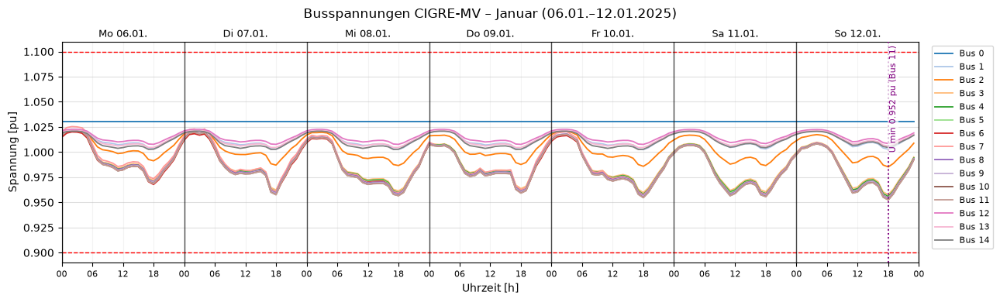

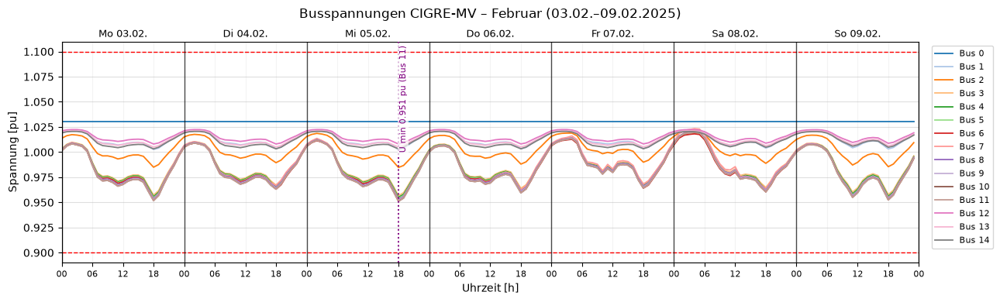

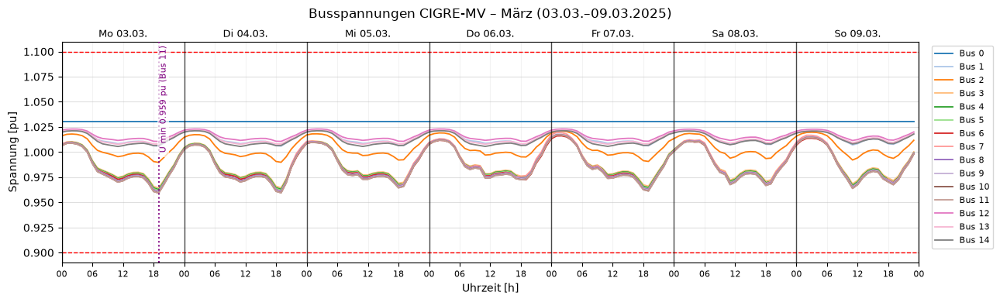

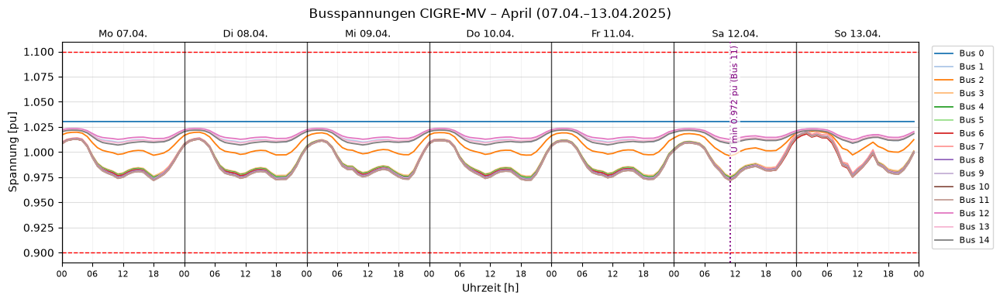

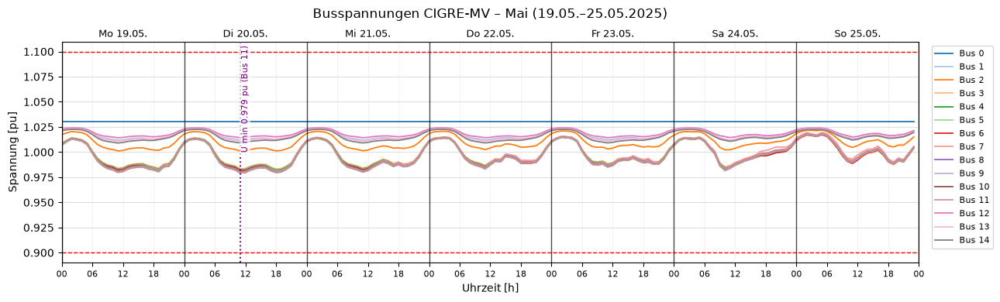

...

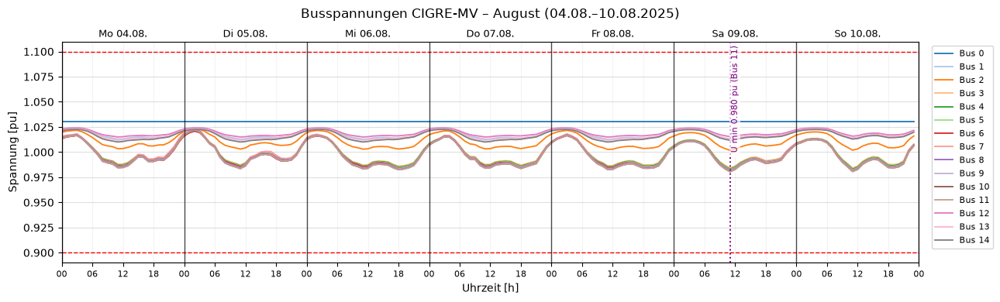

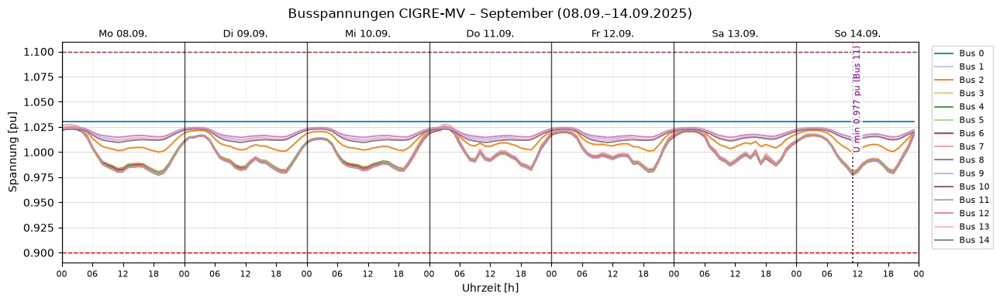

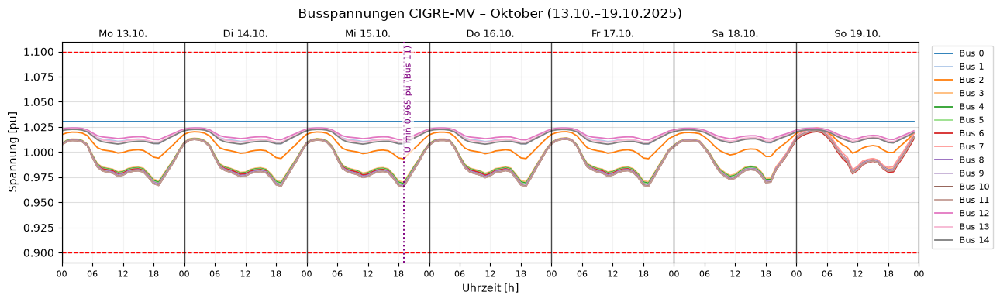

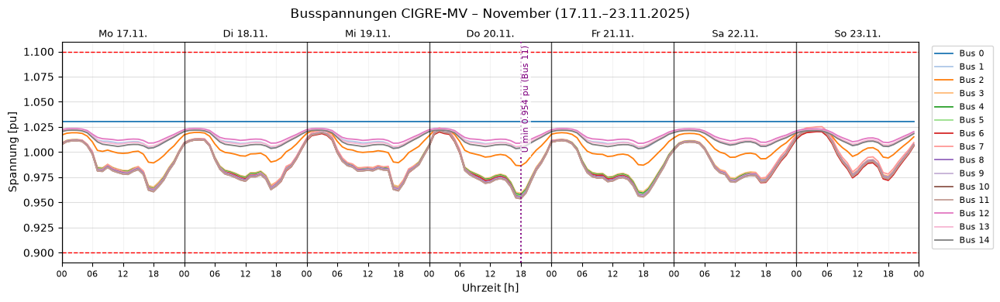

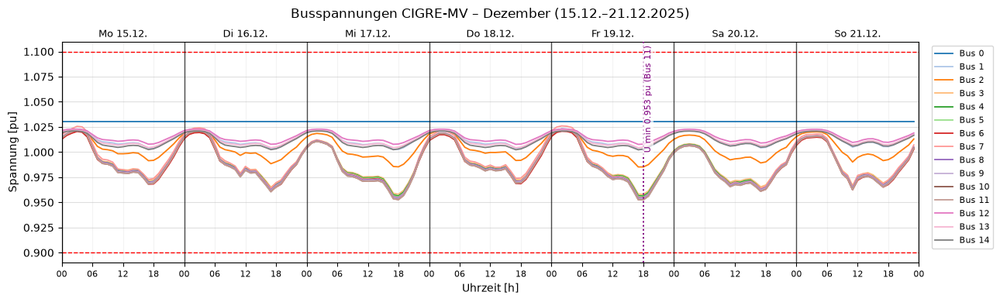

In [17]:
for m in Month:
    week = vm[res.info["month"] == m.name]
    t_min = week.min(axis=1).idxmin()
    bus_min = week.loc[t_min].idxmin()
    cigre.createDiagram(Diagram.VOLTAGE, months=m,
                        title="Busspannungen CIGRE-MV",
                        markers=[("purple", t_min, f"U min {week.loc[t_min, bus_min]:.3f} pu ({bus_min})", ":")])

### 3.5 Leitungsauslastung Monat für Monat

Je Monat ein Diagramm mit allen Leitungen, deren Trennschalter geschlossen sind. Die Leitungen 6-7, 11-4 und 14-8 führen wegen der offenen Trennschalter nur Ladestrom (unter 1 %) und sind deshalb nicht dargestellt. Rot gestrichelt ist die Grenze 100 % eingezeichnet. Die senkrechte Markierung zeigt den Zeitpunkt der höchsten Auslastung der Woche.

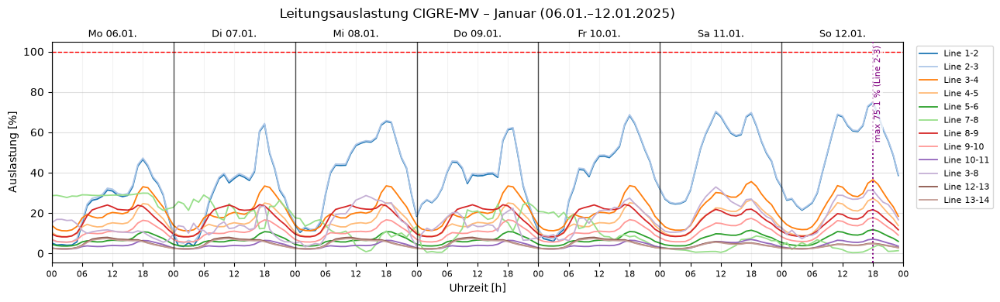

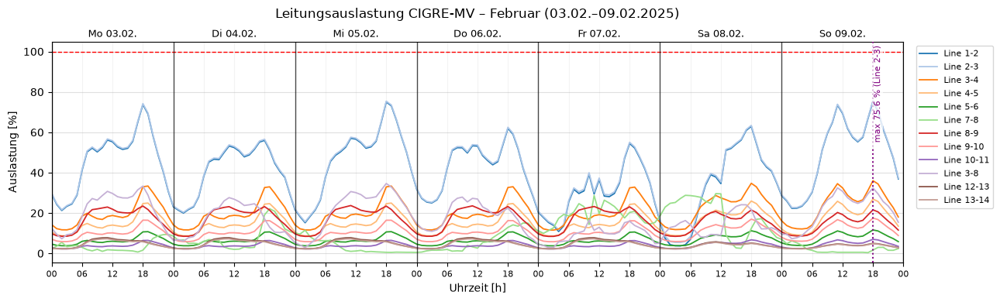

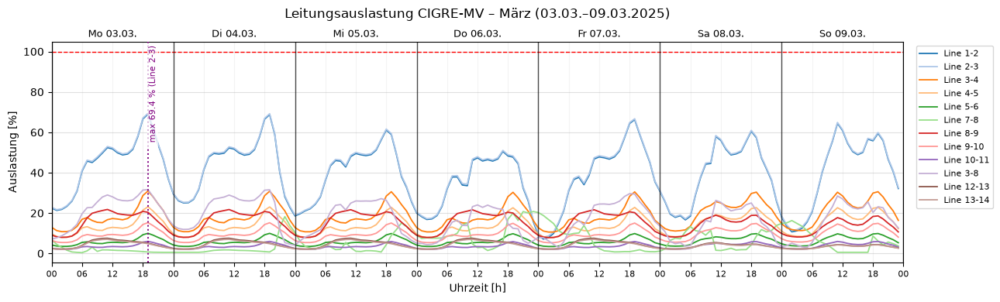

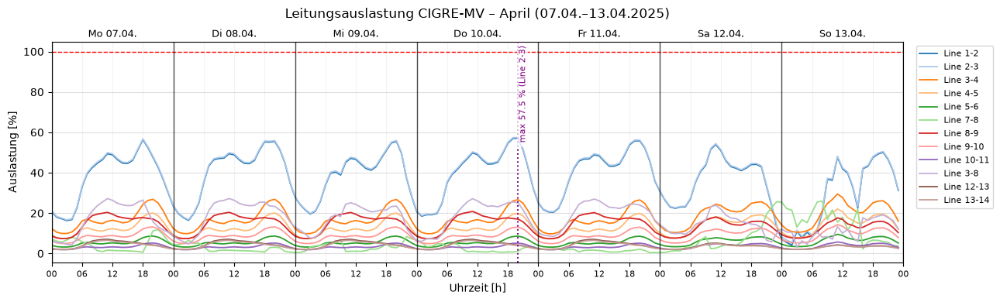

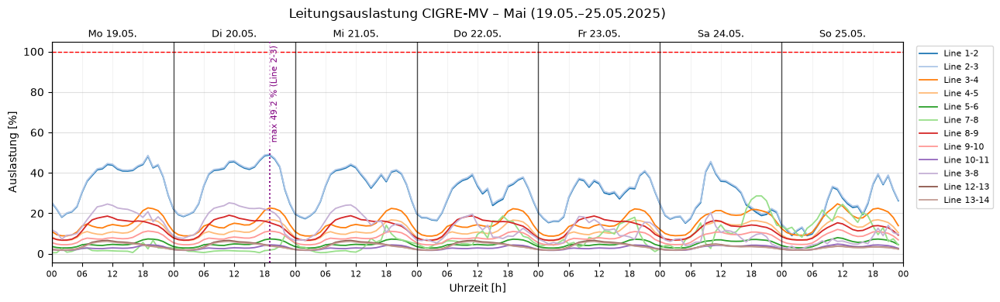

...

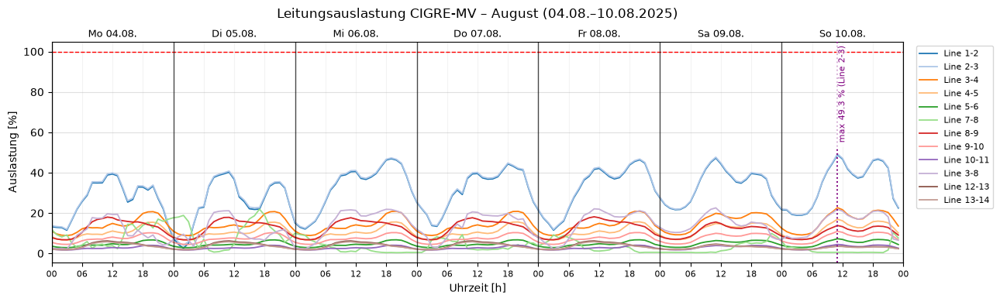

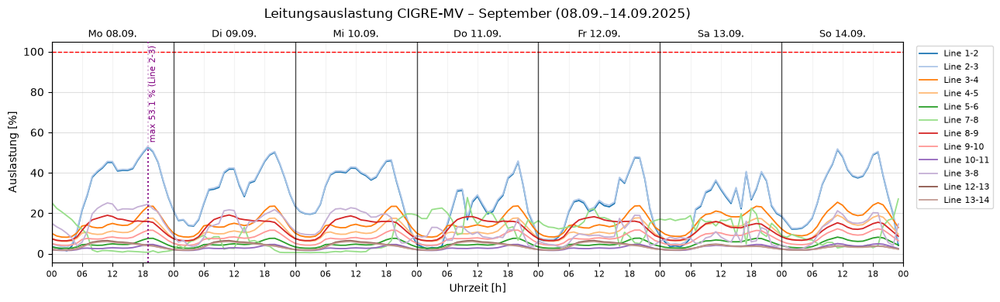

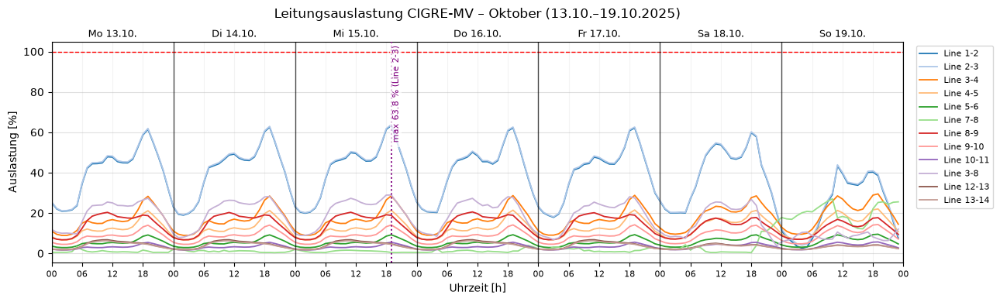

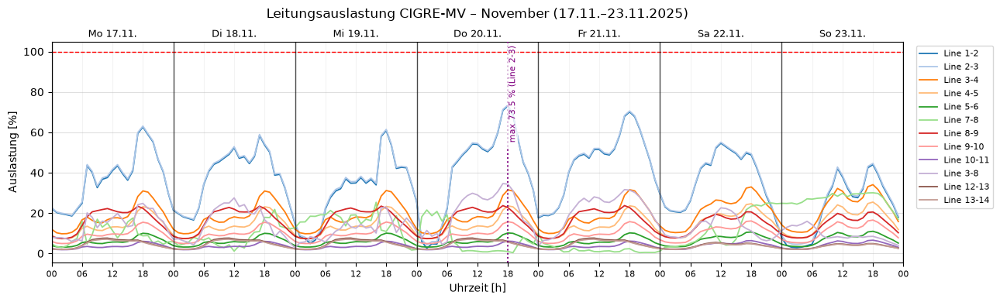

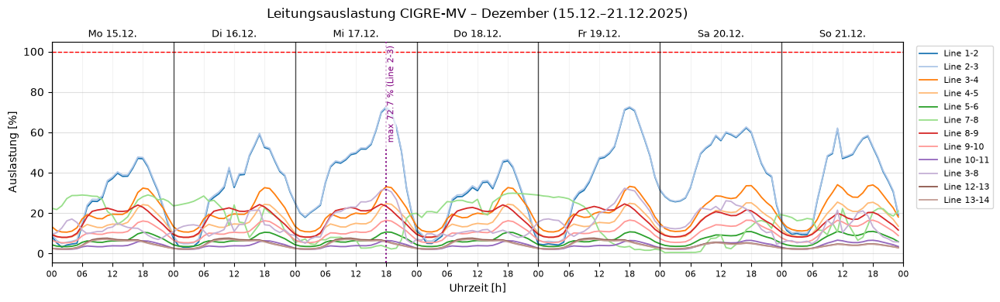

In [18]:
ll = res.line_loading
closed_lines = [n for i, n in cigre.net.line.name.items() if i not in open_lines]

for m in Month:
    week = ll.loc[res.info["month"] == m.name, closed_lines]
    t_max = week.max(axis=1).idxmax()
    line_max = week.loc[t_max].idxmax()
    cigre.createDiagram(Diagram.LINE_LOADING, elements=closed_lines, months=m,
                        title="Leitungsauslastung CIGRE-MV",
                        markers=[("purple", t_max, f"max {week.loc[t_max, line_max]:.1f} % ({line_max})", ":")])

Zur Einordnung: höchste Auslastung jeder Leitung je Monat in %.

In [19]:
l_max_month = ll[closed_lines].groupby(month_of).max().T[order]
l_max_month.index.name = "Auslastung max [%]"
plots.table(l_max_month, decimals=1, cmap="YlOrRd", vmin=0, vmax=100)

month,Januar,Februar,März,April,Mai,Juni,Juli,August,September,Oktober,November,Dezember
Auslastung max [%],,,,,,,,,,,,
Line 1-2,74.7,75.2,69.0,57.1,48.8,52.0,49.9,48.9,52.8,63.4,73.1,72.3
Line 2-3,75.1,75.6,69.4,57.5,49.2,52.4,50.3,49.3,53.1,63.8,73.5,72.7
Line 3-4,36.5,36.0,30.9,29.5,24.7,23.6,23.7,22.7,25.4,29.5,34.1,34.1
Line 4-5,27.3,26.9,23.1,22.0,18.4,17.6,17.7,16.9,19.0,22.0,25.5,25.5
Line 5-6,11.8,11.6,10.0,9.5,8.0,7.6,7.6,7.3,8.2,9.5,11.0,11.0
Line 7-8,29.9,29.6,20.8,26.0,28.6,25.9,14.4,21.9,27.8,27.0,30.1,29.9
Line 8-9,24.2,23.7,21.8,20.8,19.0,18.7,18.4,18.2,19.1,20.5,23.7,24.6
Line 9-10,17.7,17.5,15.3,14.3,12.0,11.5,11.5,11.0,12.3,14.3,16.6,16.6
Line 10-11,7.1,7.0,6.0,5.7,4.8,4.6,4.6,4.5,5.0,5.7,6.6,6.6


Die beiden Transformatoren 110/20 kV im Überblick über alle 12 Wochen:

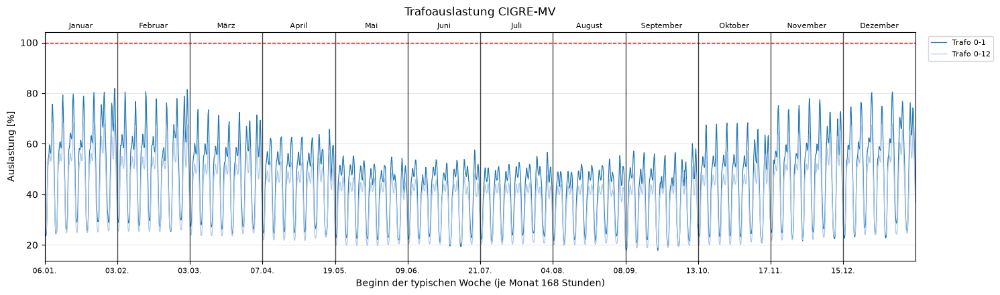

In [20]:
cigre.createDiagram(Diagram.TRAFO_LOADING, layout="overview", title="Trafoauslastung CIGRE-MV")

### 3.6 Leistungsfluss Monat für Monat

`Diagram.POWER_FLOW` zeigt für jede Stunde, wie die Leistung durch das Netz fließt:

- **Bezug externes Netz:** Leistung aus dem 110-kV-Netz (positiv = Bezug, negativ = Rückspeisung)
- **Trafo 0-1 (OS), Trafo 0-12 (OS):** Aufteilung auf die beiden Transformatoren bzw. Abgänge
- **Lasten:** gesamt und je Profil (Haushalt H25, Gewerbe G25)
- **Erzeugung:** gesamt, PV und Wind
- **Verluste:** Bezug + Erzeugung − Lasten (Leitungs- und Trafoverluste)

Jedes Diagramm besteht aus zwei Teilen. Die Erzeugung ist mit höchstens 1,7 MW viel kleiner als die Last und hat deshalb im unteren Teil eine eigene Skala. Alle Werte lassen sich mit `cigre.powerFlow()` als Tabelle abrufen.

**Energiebilanz je typischer Woche:**

In [21]:
balance = cigre.energyBalance()
plots.table(balance, decimals=1, int_cols=["Stunden Rückspeisung"])

,Bezug externes Netz [MWh],Trafo 0-1 (OS) [MWh],Trafo 0-12 (OS) [MWh],Lasten gesamt [MWh],Lasten Gewerbe [MWh],Lasten Haushalt [MWh],Erzeugung gesamt [MWh],Erzeugung PV [MWh],Erzeugung Wind [MWh],Verluste [MWh],Anteil Erzeugung an Last [%],Stunden Rückspeisung
Januar,4143.1,2191.8,1951.4,4248.8,883.3,3365.5,117.3,1.2,116.1,11.6,2.8,0
Februar,4110.8,2192.2,1918.6,4177.1,873.9,3303.2,78.5,2.8,75.7,12.2,1.9,0
März,3836.9,2052.9,1783.9,3881.9,849.1,3032.8,56.0,7.4,48.6,11.0,1.4,0
April,3613.1,1933.2,1679.9,3656.1,794.9,2861.3,52.6,7.8,44.7,9.5,1.4,0
Mai,3197.8,1697.6,1500.2,3262.5,752.3,2510.2,71.3,6.6,64.7,6.6,2.2,0
Juni,3153.3,1668.5,1484.8,3228.4,753.5,2474.9,81.7,7.3,74.3,6.6,2.5,0
Juli,3147.7,1685.6,1462.1,3180.9,713.8,2467.2,40.4,6.2,34.2,7.1,1.3,0
August,3091.8,1649.2,1442.6,3137.0,726.9,2410.1,51.8,7.1,44.7,6.6,1.7,0
September,3139.6,1656.4,1483.1,3225.1,748.1,2477.0,91.9,4.8,87.1,6.4,2.8,0
Oktober,3523.5,1890.8,1632.7,3553.3,774.1,2779.2,39.5,3.1,36.4,9.7,1.1,0


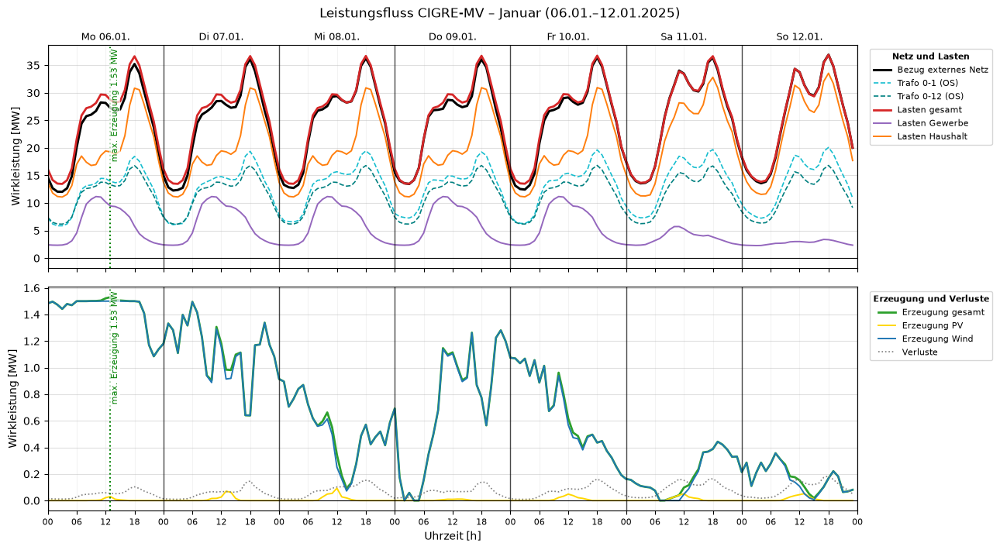

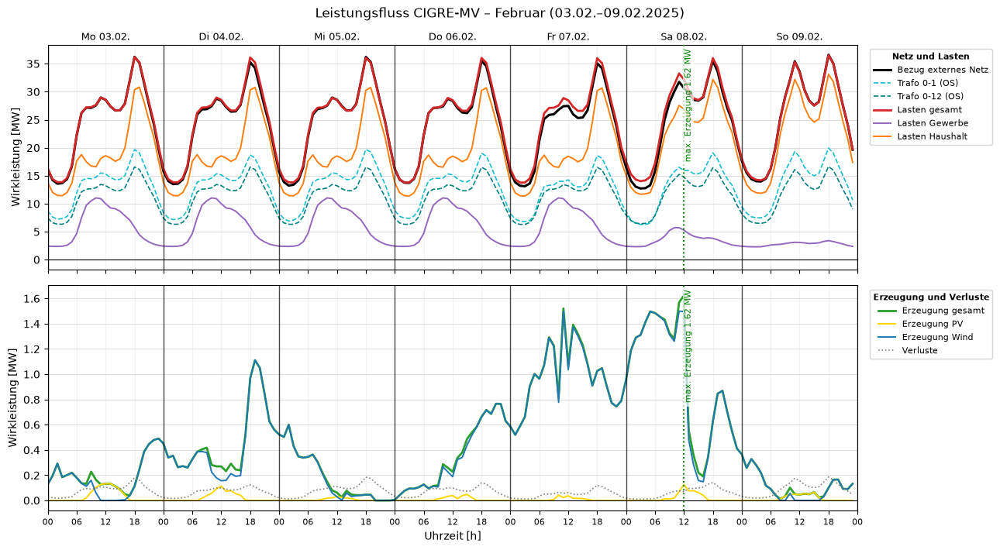

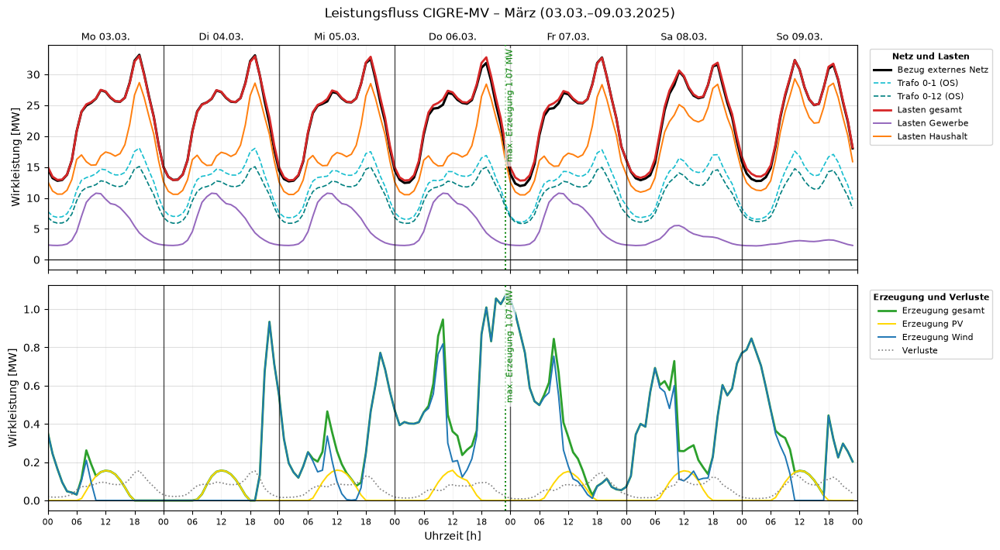

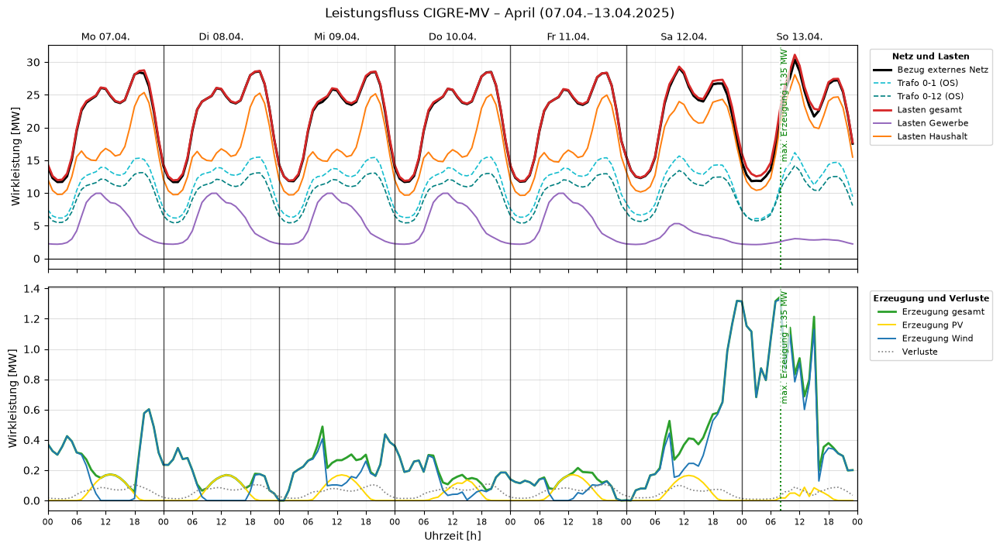

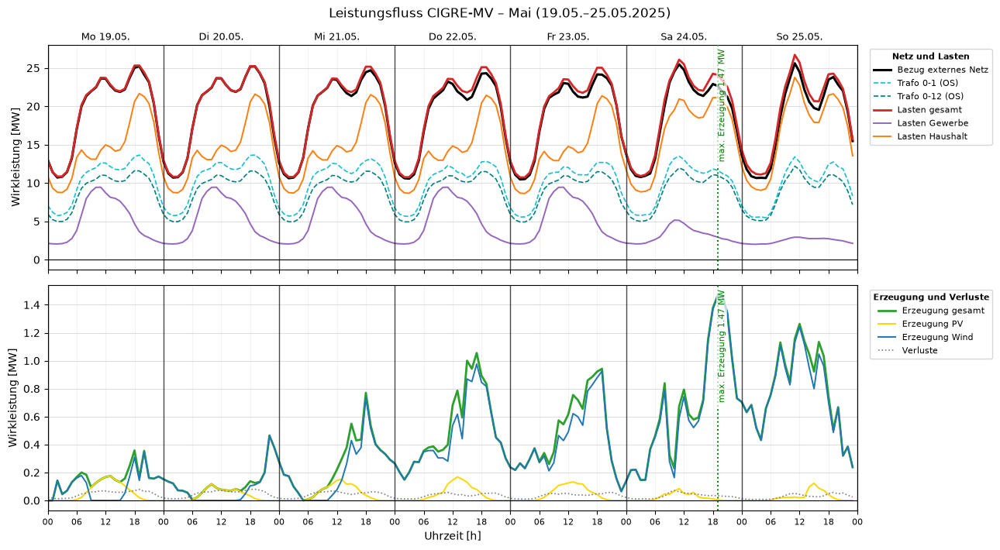

...

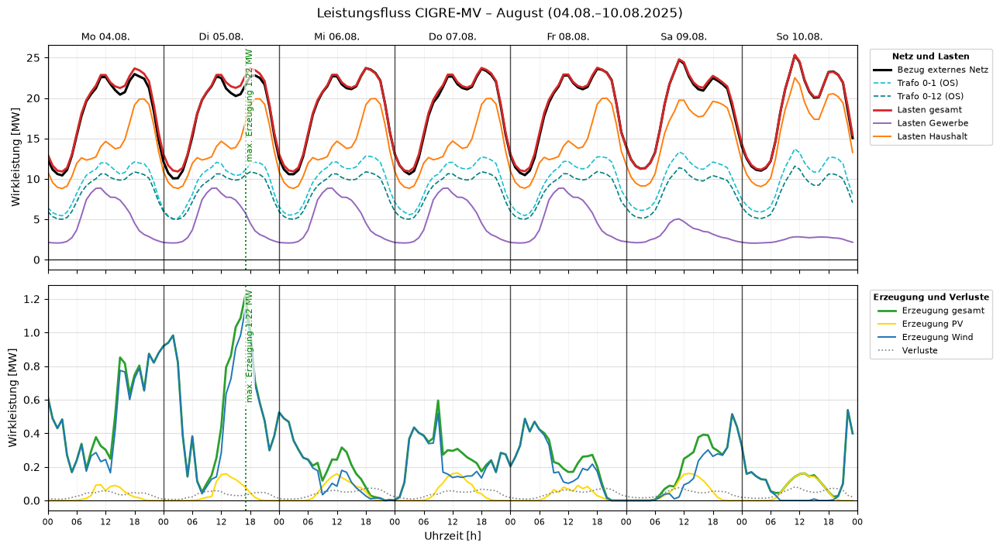

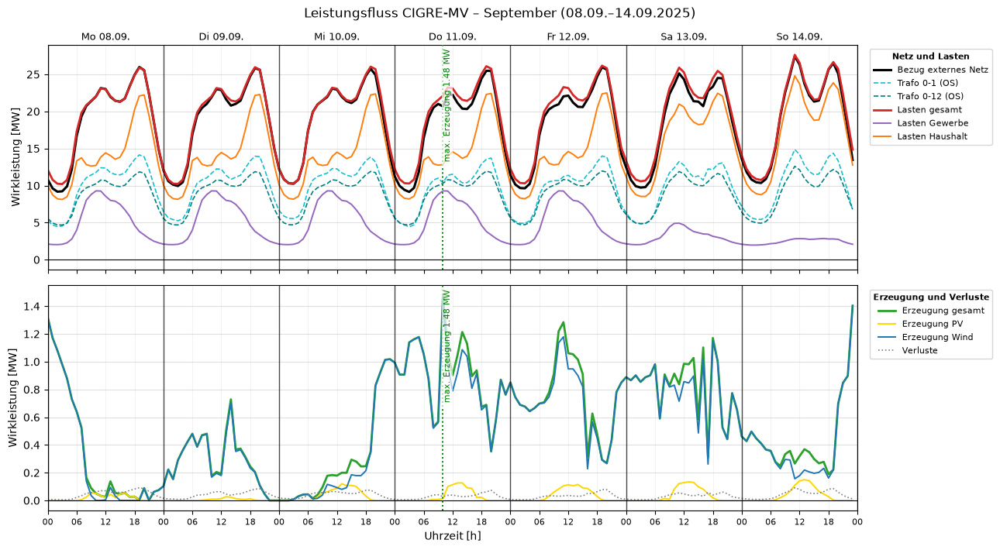

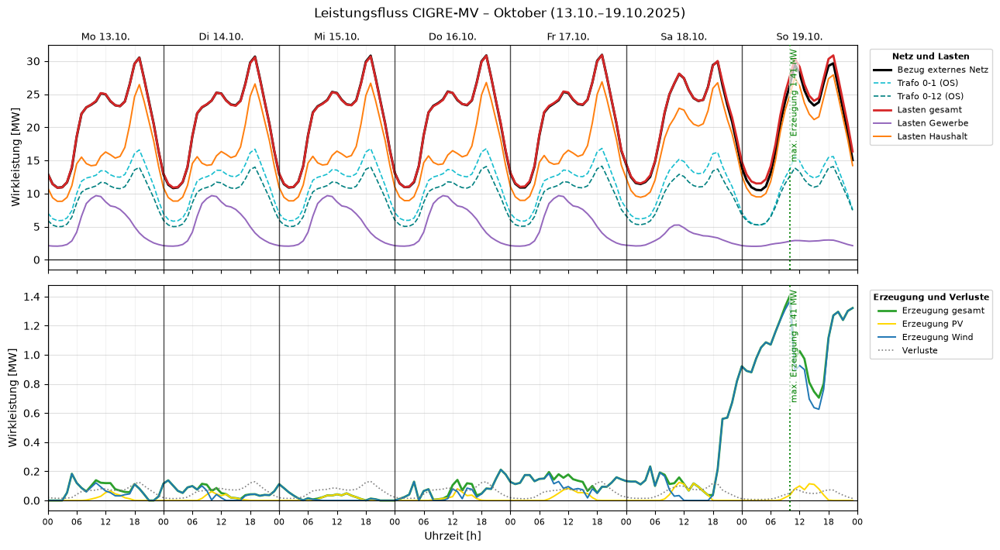

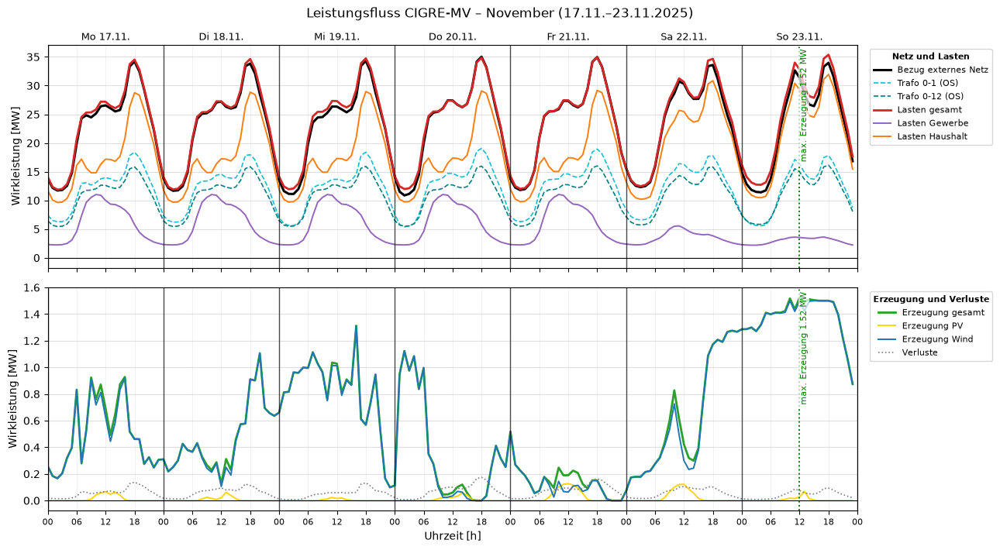

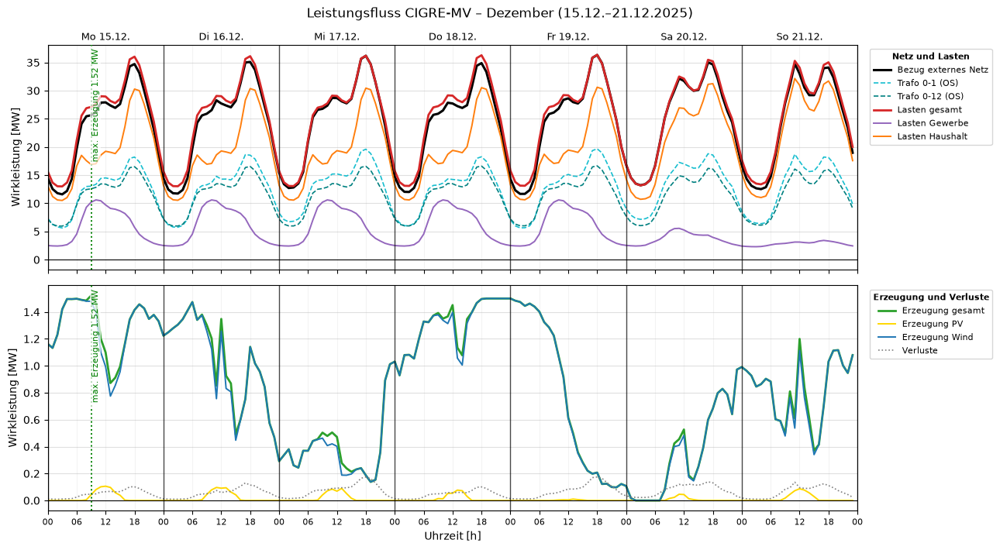

In [22]:
pf = cigre.powerFlow()

for m in Month:
    week = pf[res.info["month"] == m.name]
    t_gen = week["Erzeugung gesamt"].idxmax()
    cigre.createDiagram(Diagram.POWER_FLOW, months=m, title="Leistungsfluss CIGRE-MV",
                        markers=[("green", t_gen, f"max. Erzeugung {week.at[t_gen, 'Erzeugung gesamt']:.2f} MW", ":")])

**Einzelne Lasten und Erzeuger.** Mit `Diagram.ELEMENT_POWER` lassen sich die einzelnen `load`- und `sgen`-Elemente darstellen. Hier die PV-Anlagen und die Windenergieanlage über alle 12 Wochen (getrennt, weil die PV-Leistung sonst neben der WEA nicht zu erkennen ist) und die Lasten an Bus 1 (Haushalt und Gewerbe) im Juli und Dezember. Für einen anderen Monat oder andere Elemente `elements` und `months` anpassen.

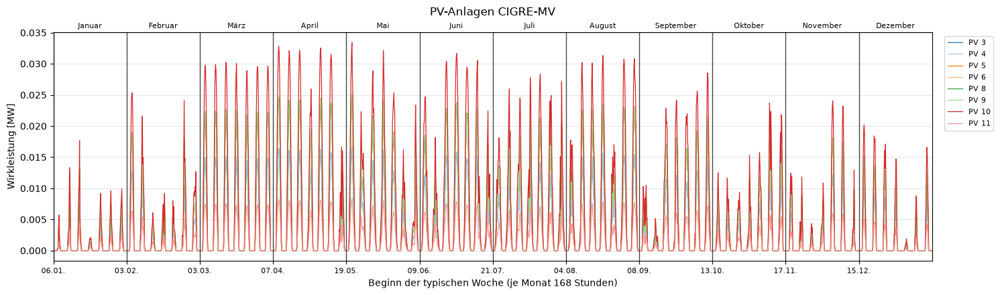

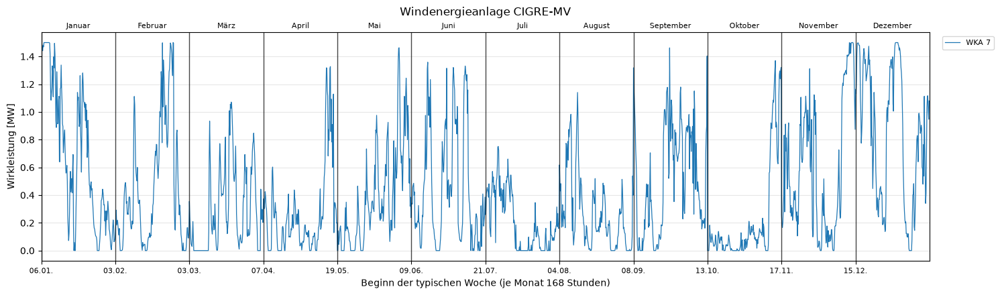

In [23]:
pv = [n for n in cigre.net.sgen.name if n.startswith("PV")]
cigre.createDiagram(Diagram.ELEMENT_POWER, elements=pv, layout="overview", title="PV-Anlagen CIGRE-MV")
cigre.createDiagram(Diagram.ELEMENT_POWER, elements=["WKA 7"], layout="overview", title="Windenergieanlage CIGRE-MV")

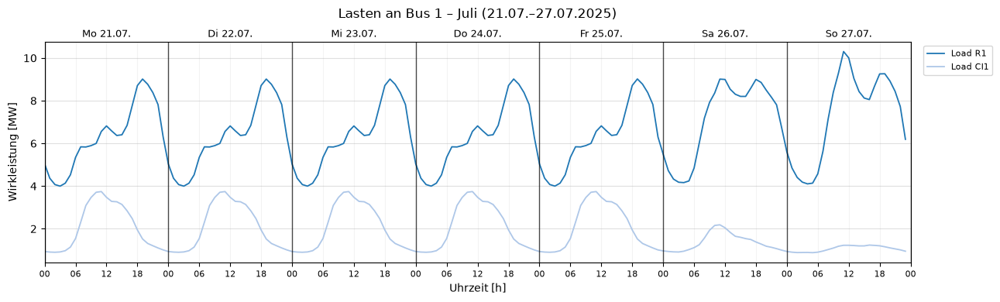

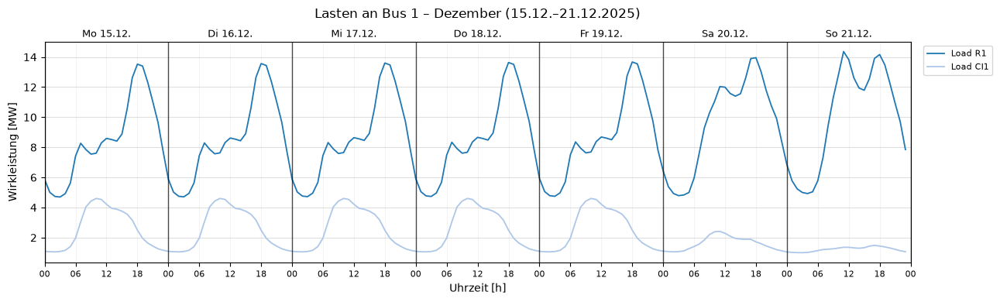

In [24]:
cigre.createDiagram(Diagram.ELEMENT_POWER, elements=["Load R1", "Load CI1"], months=[Month.JULY, Month.DECEMBER],
                    title="Lasten an Bus 1")

**Auswertung Leistungsfluss.**

- Das Netz bezieht in **jeder Stunde** Leistung aus dem 110-kV-Netz. Der Bezug liegt zwischen 9,1 MW (Septembernacht) und 36,9 MW (Januarabend). Es gibt keine Rückspeisung.
- Die beiden Transformatoren teilen sich die Last etwa im Verhältnis 53 : 47 (Trafo 0-1 : Trafo 0-12). Die Lasten an Bus 1 und Bus 12 sind gleich groß, Abgang 1 versorgt aber mehr kleine Lasten.
- Die Haushalte verbrauchen etwa 78 % der Energie, das Gewerbe 22 %. Die Bezugskurve folgt deshalb fast genau dem H25-Profil mit der Abendspitze gegen 18 Uhr.
- Die Erzeugung deckt je Woche nur 1,1 % (Oktober) bis 3,4 % (Dezember) der Last. Den Großteil liefert die Windenergieanlage. Sie erzeugt im Winter am meisten (Dezember 142 MWh je Woche, Oktober 36 MWh). Die PV-Anlagen liefern im Sommer etwa 7 MWh je Woche, im Winter 1 bis 2 MWh.
- Die Netzverluste betragen im Mittel 0,2 % der Last. Im Winter sind sie fast doppelt so hoch wie im Sommer (11,6 statt 6,6 MWh je Woche), weil die Verluste quadratisch mit dem Strom steigen.

### 3.7 Netzplan zu ausgewählten Zeitpunkten

`Diagram.NETWORK` zeichnet den Netzplan mit den Ergebnissen eines simulierten Zeitpunkts (Darstellung wie in 3.1). Der Zeitpunkt wird über `time` angegeben:

| `time` | Zeitpunkt |
|---|---|
| `"2025-07-23 13:00"` | fester Zeitpunkt (muss in einer der simulierten Wochen liegen) |
| `"min"` | niedrigste Busspannung |
| `"max"` | höchste Busspannung (ohne den Slack-Bus 0) |
| `"max_loading"` | höchste Leitungsauslastung |
| `"max_trafo"` | höchste Trafoauslastung |
| Liste, z. B. `["min", "max"]` | ein Plan je Eintrag |

Mit `months` und einem Stichwort wird der Zeitpunkt in jedem Monat gesucht und je Monat ein Plan gezeichnet. `elements=False` blendet Lasten und Erzeuger aus, `labels=False` blendet Namen und Werte aus.

**Höchste Belastung und höchste Spannung im Jahr:**

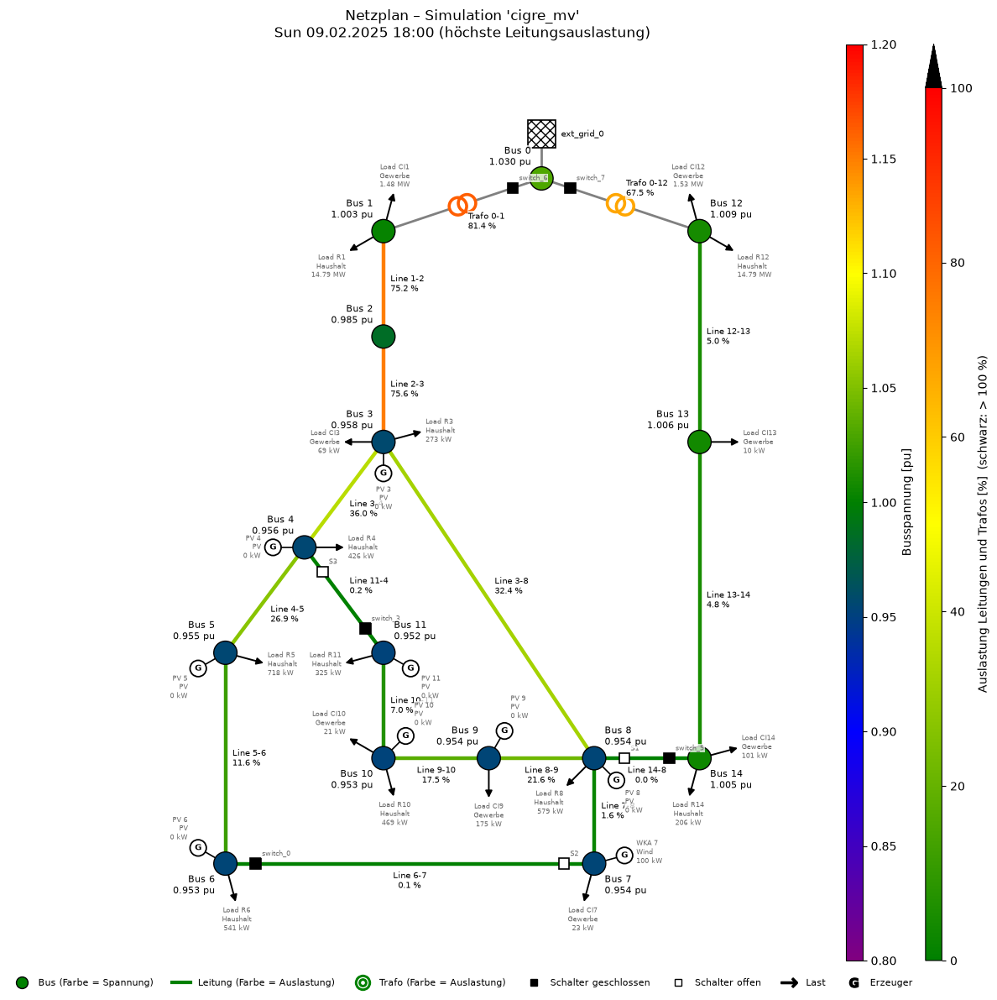

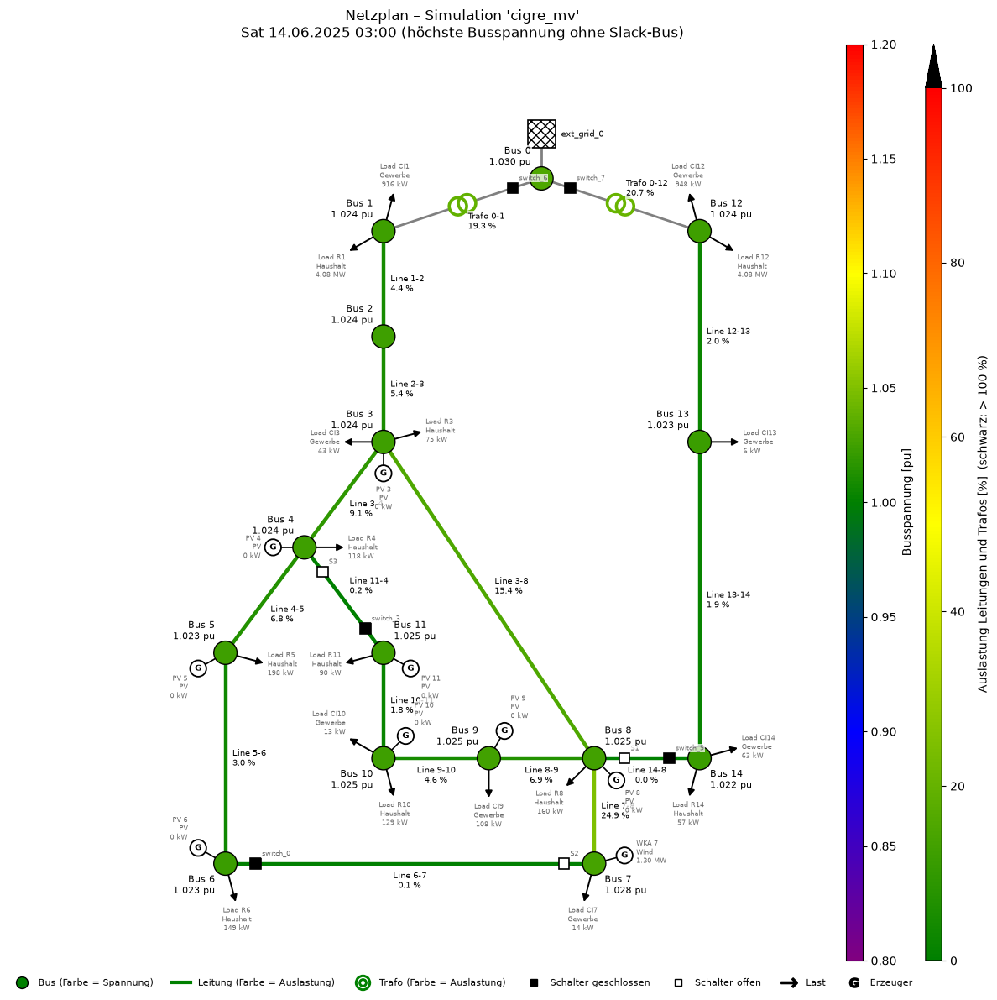

In [25]:
cigre.createDiagram(Diagram.NETWORK, time=["max_loading", "max"])

**Fester Zeitpunkt:** Sommermittag mit PV-Einspeisung.

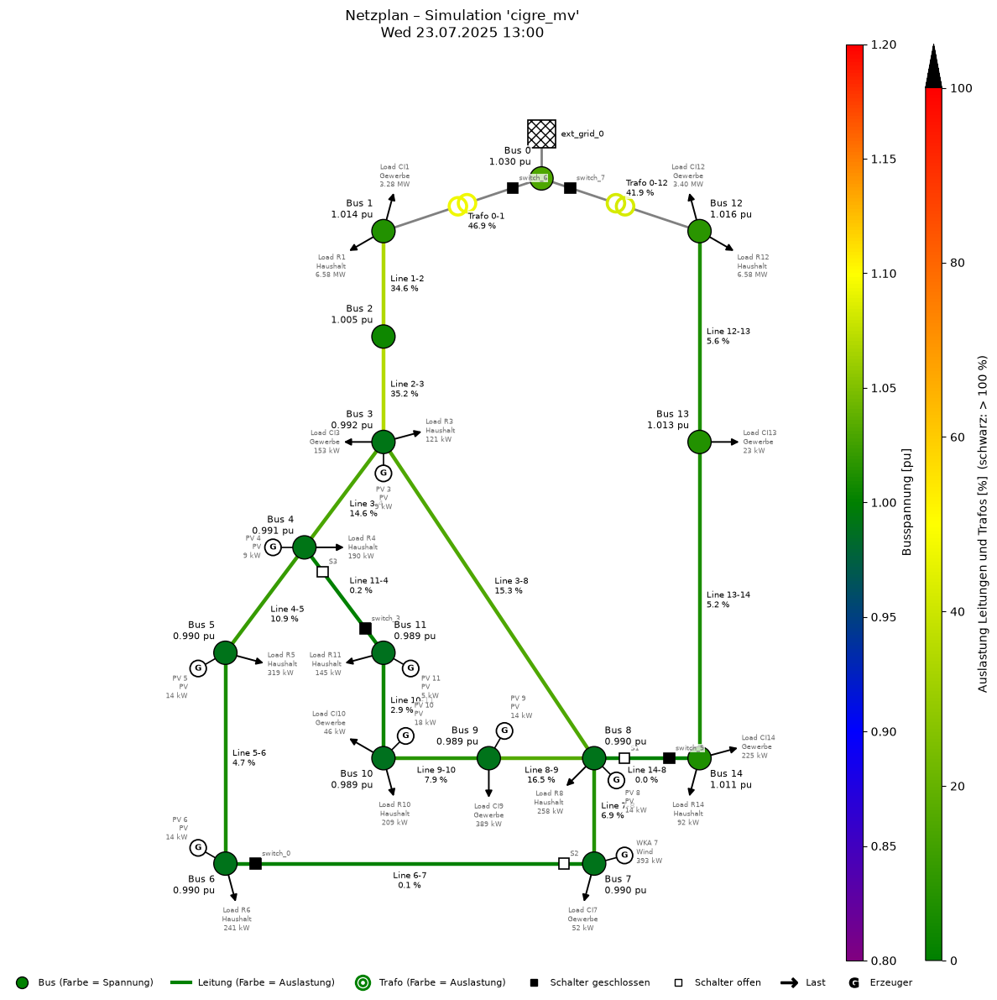

In [26]:
cigre.createDiagram(Diagram.NETWORK, time="2025-07-23 13:00")

**Niedrigste Spannung im Januar und im Juli:**

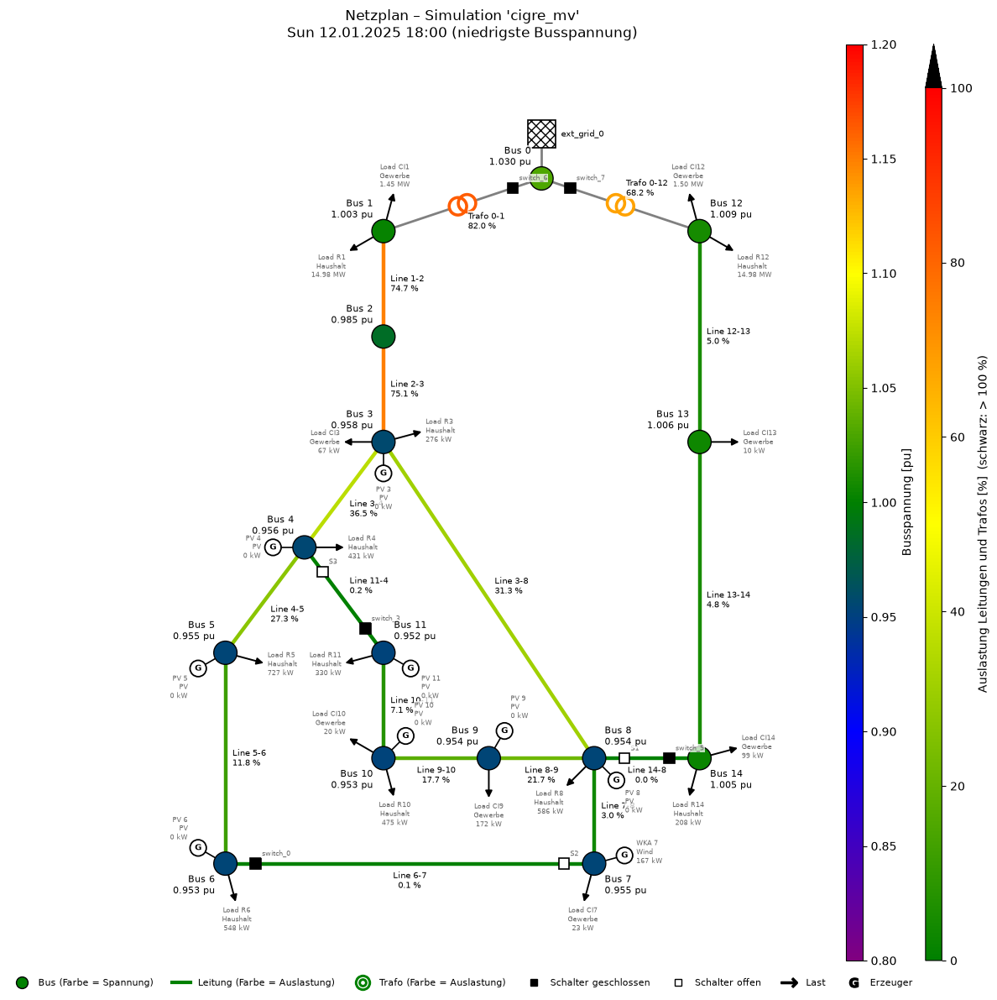

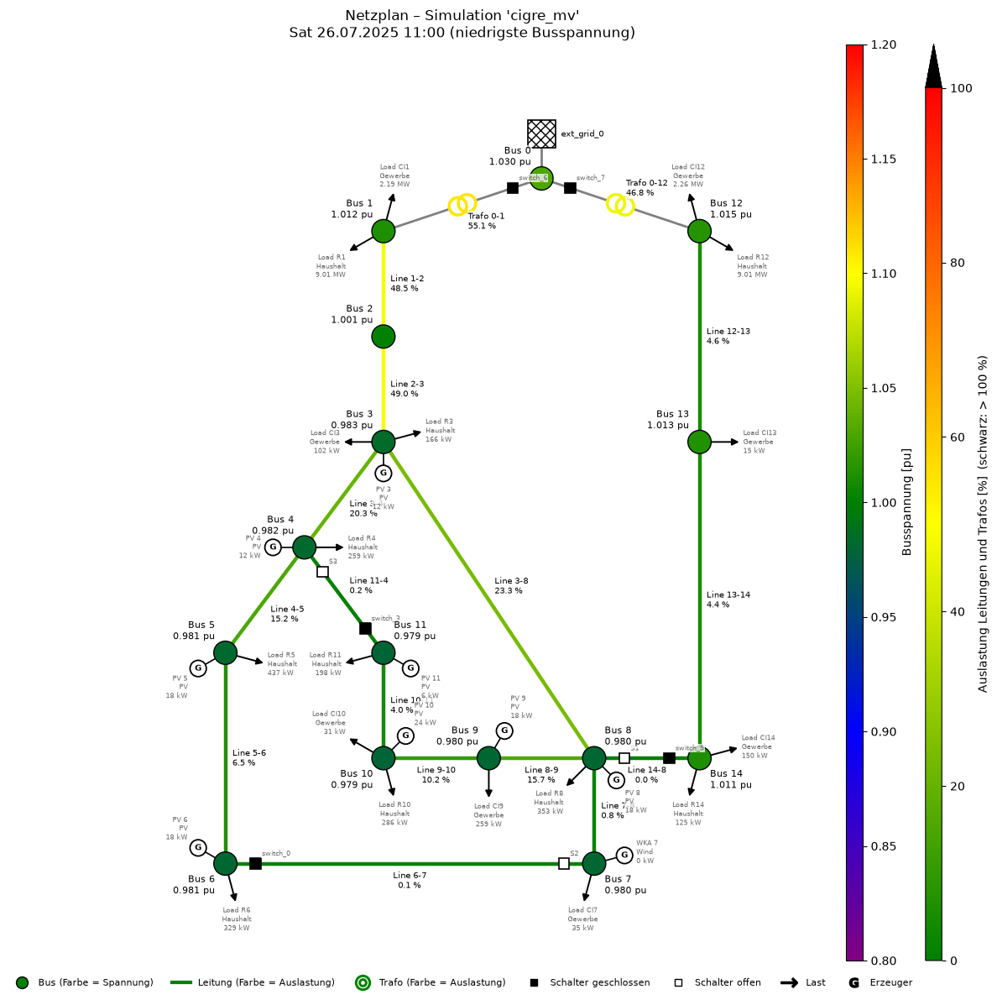

In [27]:
cigre.createDiagram(Diagram.NETWORK, time="min", months=[Month.JANUARY, Month.JULY])

### 3.8 Kennzahlen, Interpretation und Literaturabgleich

**Kennzahlen saisonale Simulation (12 typische Wochen, 2016 Stunden)**

| Größe | Wert | Ort und Zeitpunkt |
|---|---|---|
| Konvergenz | alle 2016 Lastflüsse | – |
| niedrigste Spannung | 0,951 pu | Bus 11, Mi 05.02. 18:00 |
| höchste Spannung (20 kV) | 1,028 pu | Bus 7, Sa 14.06. 03:00 |
| Stunden außerhalb 0,9 bis 1,1 pu | 0 | – |
| höchste Leitungsauslastung | 75,6 % | Line 2-3, So 09.02. 18:00 |
| Stunden mit Leitung > 100 % | 0 | – |
| höchste Trafoauslastung | 82,0 % | Trafo 0-1, So 12.01. 18:00 |
| Bezug aus dem 110-kV-Netz | 9,1 bis 36,9 MW, keine Rückspeisung | – |
| Energie Lasten / Erzeuger | 43 722 MWh / 928 MWh (Erzeugung = 2,1 % der Last) | – |

| Monat | Jan | Feb | Mär | Apr | Mai | Jun | Jul | Aug | Sep | Okt | Nov | Dez |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| U min [pu] | 0,952 | 0,951 | 0,959 | 0,972 | 0,979 | 0,978 | 0,979 | 0,980 | 0,977 | 0,965 | 0,954 | 0,953 |
| Leitung max [%] | 75,1 | 75,6 | 69,4 | 57,5 | 49,2 | 52,4 | 50,3 | 49,3 | 53,1 | 63,8 | 73,5 | 72,7 |
| Trafo max [%] | 82,0 | 81,4 | 73,6 | 65,7 | 55,2 | 57,5 | 56,6 | 55,4 | 60,1 | 68,3 | 77,9 | 80,5 |

**Interpretation.**

- **Spannungen:** In allen 2016 Stunden liegen alle Busspannungen im Band nach DIN EN 50160. Der Tiefpunkt (0,951 pu) tritt an einem Winterabend um 18 Uhr auf. Zu dieser Zeit erreicht das Haushaltsprofil H25 sein Maximum und es gibt keine PV-Einspeisung. Nachts und im Sommer steigen die Spannungen bis knapp unter die Spannung des vorgelagerten Netzes (1,03 pu). Die höchste 20-kV-Spannung (1,028 pu, Bus 7) entsteht in einer Sommernacht mit geringer Last und Windeinspeisung. Die Spannung schwankt am Ende von Abgang 1 innerhalb des Jahres um bis zu 7,4 % (Bus 11), in Abgang 2 nur um etwa 2 %.
- **Leitungen und Transformatoren:** Keine Leitung und kein Transformator ist überlastet. Die Auslastung folgt deutlich der Jahreszeit: Im Winter sind die Leitungen bis 76 % ausgelastet, im Sommer nur bis 49 bis 52 %. Ursache sind die Dynamisierung des H25-Profils (höherer Verbrauch im Winter) und das saisonale Gewerbeprofil G25. Die Tagesgänge sind in allen Wochen gleich geformt: niedrig in der Nacht, Mittagsplateau, Abendspitze gegen 18 Uhr.
- **Vergleich mit dem statischen Fall:** Die höchste Leitungsauslastung der Simulation (75,6 %) liegt **über** der des statischen Lastflusses (61,3 %), obwohl keine Last ihre Bemessungsleistung überschreitet. Im statischen Fall speisen Wind und PV mit voller Leistung ein und entlasten die Leitungen. Zur winterlichen Abendspitze liefert die PV keinen Strom und die Windenergieanlage oft nur wenig. Die Simulation liegt deshalb zwischen dem statischen Fall mit Erzeugern (61 %) und ohne Erzeuger (97 %). Die Transformatoren werden dagegen weniger belastet als im statischen Fall (82 % statt 94 %). Die großen Lasten an Bus 1 und Bus 12 erreichen ihr Maximum nicht gleichzeitig, weil das Haushalts- und das Gewerbeprofil zu verschiedenen Zeiten ihre Spitze haben.
- **Erzeugung:** Die Erzeuger decken nur 2,1 % des Verbrauchs. Es tritt keine Rückspeisung in das 110-kV-Netz auf und die Erzeugung hebt die Spannung kaum an. Das Netz ist in dieser Variante deutlich durch die Last bestimmt.

**Literaturabgleich.** 

### 3.9 Bus Spannung Vergleiche

Ich möchte hier jeweils zwei Monate gegenüberstellen, wo die PV Anlagen und Windklaftanlage viel produziert hat und die veränderung der spannung zeigen.

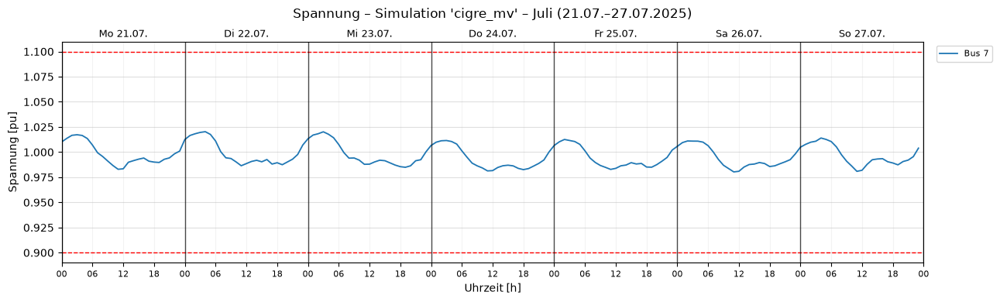

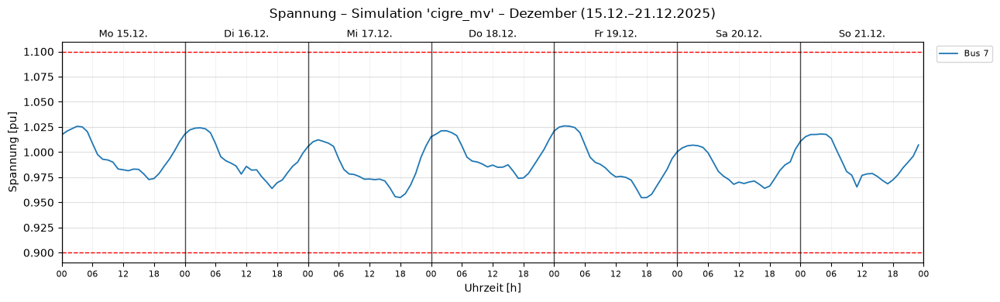

In [28]:
cigre.createDiagram(Diagram.VOLTAGE, elements=["Bus 7"], months=[Month.JULY, Month.DECEMBER])

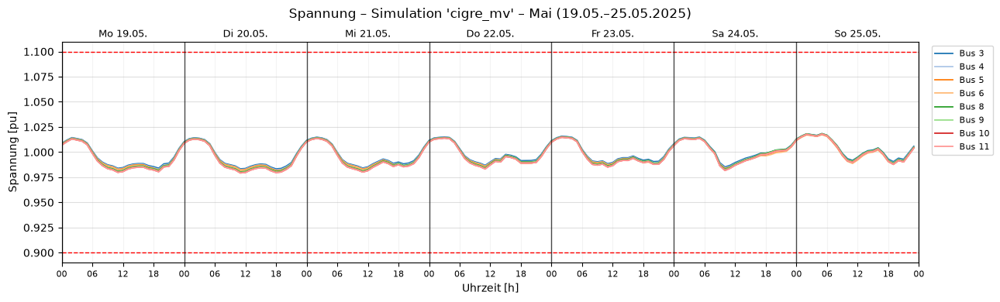

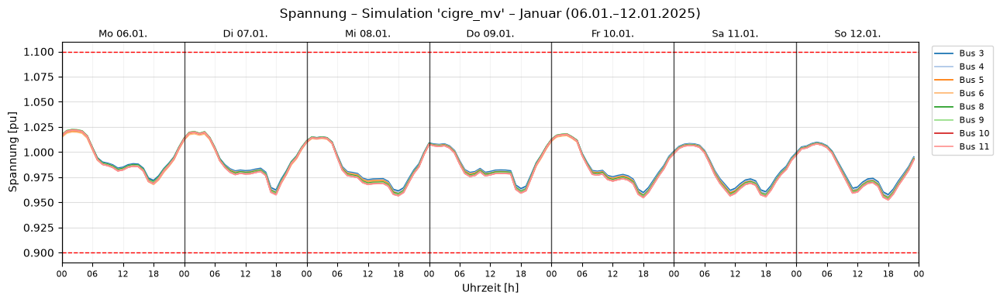

In [29]:
cigre.createDiagram(Diagram.VOLTAGE, elements=["Bus 3", "Bus 4", "Bus 5", "Bus 6", "Bus 8", "Bus 9", "Bus 10", "Bus 11"],
                    months=[Month.MAY, Month.JANUARY])